# NB-07 · Stage 7 — Teacher-output caching

**Project:** HiDMamba, hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, CPU or GPU. Nothing is trained. Expect 10 to 25 minutes; a GPU only shortens the optional recompute check at the end of section 5.

Synopsis, Stage 7: *"With DEAN, Gating, all HODs, and all Professors now frozen, precompute and persist to disk: Professor per-subclass logits, Professor penultimate embeddings, Gating routing distributions g(x), and DEAN's SSM output sequences, for every training sample, once."* The Chief Resident (Stage 8) is then trained against these files and never runs a teacher.

Most of those arrays were already written by the notebooks that produced the teachers (NB-02 to NB-06). This notebook therefore does three jobs instead of recomputing anything:

1. **Collects** them into one self-describing package (`cache/` + `teacher_cache_manifest.json` + `cache_lib.py`) that Stage 8 can attach as a single Dataset.
2. **Proves** that the package is consistent: every array has the row order of `split_idx.npz`, every column has the label order it claims, nothing is non-finite, nothing comes from fold 10, and (when the signals are attached) a fresh forward pass of DEAN and of the heads reproduces the cached values.
3. **Audits the targets** the Chief Resident will imitate. Stage 6 showed that the Professors fit the training labels almost perfectly (training AUC about 1.0, validation about 0.93). Their training-set logits are therefore sharper than anything the Chief Resident will see at test time. This notebook measures that gap source by source and stores sharpness-matched variants of the in-sample logits as an optional target, so that Stage 8 can ablate "literal" against "matched" targets instead of guessing.

### Inputs (attach these Datasets)
| Dataset | Files used |
|---|---|
| `dean-finetuned-v2` (NB-02 v2) | `split_idx.npz`, `calibration.json`, `eval_lib.py`, `dean_lib.py`, `dean_finetuned.pt`, `dean_logits_{train,val}.npy`, `dean_logits_train_oof.npy`, `dean_emb_{train,val}.npy`, `dean_tokens_{train,val}_fp16.npy` |
| `gating-network-v2` (NB-03 v2) | `routing_distributions.npy`, `routing_distributions_insample.npy`, `routing_val.npy` (and `gating.pt`, `gating_lib.py`) |
| `departmental-heads-v1` (NB-05 output) | `hod_logits_{train,val}.npy`, `hods/hod_*_deploy.pt`, `hod_lib.py` |
| `professors-v2` (NB-05 Stage 6 v2 output) | the Professor logits (n x 21) and embeddings (n x 21 x d) for train and validation, found by shape (see section 3) |
| `ptbxl-processed-v1` (Stage 1) | `labels_multihot.csv`; `ptbxl_100hz.npy` is only used by the optional recompute check and the record cards |

### Outputs (`/kaggle/working`, publish as the Dataset `cached-teacher-outputs-v1`)
| File | Content |
|---|---|
| `cache/*.npy`, `teacher_cache_manifest.json` | all arrays with shape, dtype, md5 and provenance |
| `cache_lib.py` | `load_cache`, `verify_cache`, the Gram function used for relational distillation |
| `cache_report.json`, `tables/*.csv` | the checks and the target audit, for the paper |
| `figures/*.png|pdf` | 16 figures, 7.2 inches wide (a double-column journal figure), 300 dpi |

### What goes into `cache/` (n_train = 17,418, n_val = 2,183, 26 labels = 5 superclasses + 21 subclasses)
| Array | Shape | Used by Stage 8 for |
|---|---|---|
| `y_train`, `y_val` | n x 26 | supervised loss |
| `logit_offset` | 26 | `log(pos_weight)` of every label: raw logits of all networks carry this offset |
| `dean_logits_train_oof`, `dean_logits_train_insample`, `dean_logits_val` | n x 26 | alternative or additional logit targets and the teacher reference |
| `dean_tokens_train`, `dean_tokens_val` | n x 40 x 256, fp16 | the "SSM output sequence" of the synopsis |
| `dean_gram_train`, `dean_gram_val` | n x 40 x 40, fp16 | the relational target of the RKD term, precomputed |
| `dean_emb_train`, `dean_emb_val` | n x 256 | embeddings for the prototype index and diagnostics |
| `hod_logits_train`, `hod_logits_val` | n x 26 | HOD committee targets (ablation arm) |
| `prof_logits_train`, `prof_logits_val` | n x 21 | the logit-distillation target of the synopsis |
| `prof_emb_train`, `prof_emb_val` | n x 21 x d, fp16 | keys and values of the Consultation module |
| `prof_reliable` | 21 | which Professors have at least 10 validation positives |
| `route_train`, `route_val`, `route_train_insample` | n x 5 | gate-mimic target g(x) (cross-fitted for training) |
| `*_matched` | n x 26 or n x 21 | in-sample logits divided by a per-source temperature (section 7) |
| `ecg_id_train`, `ecg_id_val`, `fold_train` | n | row keys |

### Decisions that interpret the written plan
* **Nothing is retrained and nothing is recomputed unless it has to be.** Recomputing a Professor from its checkpoint would make the cache depend on the exact library version of NB-06; the cached outputs of NB-06 are used and checked instead (section 5).
* **Gate target.** `route_train` is the *cross-fitted* routing distribution of NB-03 (each record is routed by a gate that did not train on it). The in-sample version is stored for comparison only.
* **Logits stay raw.** Every network in the project was trained with capped positive weights, so a raw logit equals the calibrated logit plus `log(pos_weight)`. The cache stores raw logits plus `logit_offset`; calibration is a Platt map fitted on fold 9 and written to `cache_report.json`.
* **Fold 10 never appears.** Not in the arrays, not in the labels, not in any figure.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, shutil, warnings, platform, importlib, hashlib
from collections import OrderedDict

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, rankdata
from scipy.optimize import brentq

warnings.filterwarnings('ignore')
NB_T0 = time.time()

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
CACHE_DIR = os.path.join(WORK, 'cache')
FIG_DIR = os.path.join(WORK, 'figures')
TAB_DIR = os.path.join(WORK, 'tables')
for d in (CACHE_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

try:
    import torch
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    HAVE_TORCH = True
except Exception:
    torch, dev, HAVE_TORCH = None, None, False

VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'torch': torch.__version__ if HAVE_TORCH else None}
print(VERSIONS)
print('device', dev, '| work', WORK)

{'python': '3.13.15', 'numpy': '2.1.3', 'pandas': '2.3.3', 'torch': '2.11.0+cu128'}
device cuda | work /kaggle/working


## 1. Configuration
`min_pos` is the same reliability rule as in every earlier notebook: a label is averaged and used for selection only if fold 9 holds at least 10 positives of it. `n_check` is the number of records used by the optional recompute check.

In [2]:
CFG = dict(
    seed=42, min_pos=10, n_boot=200,
    n_check=256,                 # records for the recompute check (section 5)
    recompute_check=True,        # needs the signals, dean_finetuned.pt, dean_lib.py, hod_lib.py and the HOD deploy files
    match_sharpness=True,        # section 7
    gram_chunk=512,
    strict=True,                 # a failed check stops the export
)
print(CFG)

{'seed': 42, 'min_pos': 10, 'n_boot': 200, 'n_check': 256, 'recompute_check': True, 'match_sharpness': True, 'gram_chunk': 512, 'strict': True}


## 2. Libraries
`eval_lib.py` comes from the NB-02 Dataset, so calibration, bootstrap and AUC are computed with exactly the code that produced the teacher's numbers. `cache_lib.py` is written below and is also what Stage 8 imports.

In [3]:
%%writefile cache_lib.py
"""Teacher cache of HiDMamba (stage 7): schema, loader and verifier.

Every array in the cache has the row order of split_idx.npz (training records in train_idx order,
validation records in val_idx order). Fold 10 is never part of the cache.
"""
import os, json, hashlib
import numpy as np

SCHEMA_VERSION = 1
MANIFEST = 'teacher_cache_manifest.json'


def token_gram_np(tok):
    # (B,L,D) -> (B,L,L): cosine similarity between the tokens of one record after removing the record's mean token.
    # Same definition as hod_lib.token_gram, the quantity the Gram-RKD term of stages 5, 6 and 8 compares.
    t = np.asarray(tok, dtype=np.float32)
    t = t - t.mean(axis=1, keepdims=True)
    t = t / np.maximum(np.linalg.norm(t, axis=-1, keepdims=True), 1e-6)
    return np.matmul(t, np.transpose(t, (0, 2, 1)))


def linear_cka(X, Y):
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    hsic = np.linalg.norm(X.T @ Y, 'fro') ** 2
    return float(hsic / (np.linalg.norm(X.T @ X, 'fro') * np.linalg.norm(Y.T @ Y, 'fro') + 1e-12))


def md5_file(path, chunk=1 << 24):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def load_manifest(root):
    return json.load(open(os.path.join(root, MANIFEST)))


def load_cache(root, only=None, mmap=True):
    """Returns (manifest, {name: array}). Large arrays are memory-mapped unless mmap=False."""
    man = load_manifest(root)
    out = {}
    for k, m in man['arrays'].items():
        if only is not None and k not in only:
            continue
        out[k] = np.load(os.path.join(root, m['file']), mmap_mode='r' if mmap else None)
    return man, out


def verify_cache(root, deep=False):
    """Checks that every file of the manifest exists with the recorded shape and dtype (and md5 when deep=True)."""
    man = load_manifest(root)
    problems = []
    for k, m in man['arrays'].items():
        p = os.path.join(root, m['file'])
        if not os.path.exists(p):
            problems.append(f'{k}: file missing'); continue
        a = np.load(p, mmap_mode='r')
        if list(a.shape) != list(m['shape']) or str(a.dtype) != m['dtype']:
            problems.append(f'{k}: expected {m["shape"]} {m["dtype"]}, found {list(a.shape)} {a.dtype}')
        elif deep and md5_file(p) != m['md5']:
            problems.append(f'{k}: md5 differs')
    return problems

Writing cache_lib.py


In [4]:
def find_all(name):
    hits = []
    for root in (WORK, INPUT_ROOT):
        hits += glob.glob(f'{root}/**/{name}', recursive=True)
    seen, out = set(), []
    for h in sorted(hits):
        if os.path.abspath(h).startswith(CACHE_DIR + os.sep):        # never read our own output back as an input
            continue
        rp = os.path.realpath(h)
        if rp not in seen:
            seen.add(rp); out.append(h)
    return out

sys.path.insert(0, WORK)
_src = find_all('eval_lib.py')
assert _src, 'eval_lib.py not found. Attach the Dataset dean-finetuned-v2.'
if os.path.abspath(_src[0]) != os.path.join(WORK, 'eval_lib.py'):
    shutil.copy(_src[0], os.path.join(WORK, 'eval_lib.py'))
import eval_lib, cache_lib
importlib.reload(eval_lib); importlib.reload(cache_lib)
from eval_lib import sigmoid, auc_per_label, tune_thresholds, bootstrap, paired_delta, reliability, fit_calibration
from cache_lib import token_gram_np, linear_cka, md5_file

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
W2, W1 = 7.2, 3.5            # figure widths in inches: double column, single column
mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7.5,
    'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.4, 'legend.frameon': False, 'pdf.fonttype': 42, 'axes.linewidth': 0.6,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'lines.linewidth': 1.0,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
SRC_COL = {'DEAN (in-sample)': '#999999', 'DEAN (out-of-fold)': '#333333', 'HOD committee': '#0072B2', 'Professors': '#D55E00'}
FAMILY = {
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI', 'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight', pad_inches=0.04)
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', pad_inches=0.04)
    plt.show()

def panel(ax, s):
    ax.text(-0.02, 1.04, s, transform=ax.transAxes, fontsize=8.5, fontweight='bold', va='bottom', ha='right')
print('libraries ready | eval_lib from', _src[0])

libraries ready | eval_lib from /kaggle/input/datasets/iaadidevresearch/error-v1-results-stage-6-professor-distillation/eval_lib.py


## 3. Locating the artefacts
Every input is looked up by file name in the working directory and in every attached Dataset. If a file exists more than once (the Stage 6 output repeats the Stage 5 files, for example), the copies are compared and the notebook stops if they disagree: two different `hod_logits_train.npy` files would mean two different experiments are attached.

The Stage 6 outputs are found **by shape**, not by exact name: a file `prof*logit*.npy` with shape (n, 21) and a file `prof*emb*.npy` with shape (n, 21, d), where n is 17,418 (training) or 2,183 (validation). If a name does not match, the error lists what was found.

In [5]:
HINT = {
    'labels_multihot.csv': 'ptbxl-processed-v1', 'ptbxl_100hz.npy': 'ptbxl-processed-v1',
    'split_idx.npz': 'dean-finetuned-v2', 'calibration.json': 'dean-finetuned-v2', 'dean_finetuned.pt': 'dean-finetuned-v2',
    'dean_lib.py': 'dean-finetuned-v2', 'dean_logits_train.npy': 'dean-finetuned-v2', 'dean_logits_train_oof.npy': 'dean-finetuned-v2',
    'dean_logits_val.npy': 'dean-finetuned-v2', 'dean_emb_train.npy': 'dean-finetuned-v2', 'dean_emb_val.npy': 'dean-finetuned-v2',
    'dean_tokens_train_fp16.npy': 'dean-finetuned-v2', 'dean_tokens_val_fp16.npy': 'dean-finetuned-v2',
    'routing_distributions.npy': 'gating-network-v2', 'routing_distributions_insample.npy': 'gating-network-v2', 'routing_val.npy': 'gating-network-v2',
    'hod_logits_train.npy': 'departmental-heads-v1 (the Stage 5 output)', 'hod_logits_val.npy': 'departmental-heads-v1 (the Stage 5 output)',
}

def same_array(p, q, atol=1e-2):
    a, b = np.load(p, mmap_mode='r'), np.load(q, mmap_mode='r')
    if a.shape != b.shape:
        return False
    step = max(1, 2_000_000 // max(1, int(np.prod(a.shape[1:], dtype=np.int64))))
    for i in range(0, len(a), step):
        if not np.allclose(np.asarray(a[i:i + step], dtype=np.float32), np.asarray(b[i:i + step], dtype=np.float32), atol=atol, rtol=1e-3):
            return False
    return True

REG = OrderedDict()            # name -> dict(path, mb, copies)
def pick(name, required=True):
    hits = find_all(name)
    if not hits:
        if required:
            raise FileNotFoundError(f'{name} not found. Attach the Dataset {HINT.get(name, "that contains it")}.')
        return None
    if len(hits) > 1 and name.endswith('.npy'):
        bad = [h for h in hits[1:] if not same_array(hits[0], h)]
        if bad:
            raise RuntimeError(f'{name} exists in several places with different content:\n  ' + '\n  '.join([hits[0]] + bad) +
                               '\nDetach one of the Datasets so that only one experiment is attached.')
    REG[name] = dict(path=hits[0], mb=os.path.getsize(hits[0]) / 1e6, copies=len(hits))
    return hits[0]

P = {n: pick(n) for n in HINT if n not in ('ptbxl_100hz.npy', 'dean_finetuned.pt', 'dean_lib.py')}
for n in ('ptbxl_100hz.npy', 'dean_finetuned.pt', 'dean_lib.py'):
    P[n] = pick(n, required=False)
for n in ('hod_lib.py', 'gating_lib.py', 'gating.pt', 'hod_calibration.json', 'routing_probs_train_oof.npy'):
    P[n] = pick(n, required=False)
print(pd.DataFrame(REG).T.assign(path=lambda d: d.path.str.replace(INPUT_ROOT, '<input>', regex=False).str.replace(WORK, '<work>', regex=False)).to_string())

                                                                                                                                            path           mb copies
labels_multihot.csv                                                         <input>/notebooks/iaadidev/00-data-prep-hidmamba/labels_multihot.csv     1.299222      1
split_idx.npz                                     <input>/datasets/iaadidevresearch/results-stage-3-dean-supervised-fine-tuning-v2/split_idx.npz     0.473264      1
calibration.json                               <input>/datasets/iaadidevresearch/results-stage-3-dean-supervised-fine-tuning-v2/calibration.json     0.003265      1
dean_logits_train.npy                     <input>/datasets/iaadidevresearch/results-stage-3-dean-supervised-fine-tuning-v2/dean_logits_train.npy       1.8116      1
dean_logits_train_oof.npy             <input>/datasets/iaadidevresearch/results-stage-3-dean-supervised-fine-tuning-v2/dean_logits_train_oof.npy       1.8116      1
dean_logit

In [6]:
# row counts come from the split file, everything else is checked against them
split = np.load(P['split_idx.npz'], allow_pickle=True)
tr_idx, va_idx = split['train_idx'], split['val_idx']
LABELS = [str(x) for x in split['label_columns']]
assert LABELS[:5] == SUPER and len(LABELS) == 26, LABELS
SUB = LABELS[5:]
NTR, NVA = len(tr_idx), len(va_idx)
print(f'train {NTR} | val {NVA} | labels {len(LABELS)} ({len(SUPER)} super + {len(SUB)} sub)')

def shape_candidates(patterns, ndim, n_rows, n_cols=None):
    cands = []
    for pat in patterns:
        for h in find_all(pat):
            if h in cands or not h.endswith('.npy'):
                continue
            try:
                a = np.load(h, mmap_mode='r')
            except Exception:
                continue
            if a.ndim == ndim and a.shape[0] == n_rows and (n_cols is None or a.shape[1] == n_cols):
                cands.append(h)
    return cands

def pick_by_shape(label, patterns, ndim, n_rows, n_cols):
    c = shape_candidates(patterns, ndim, n_rows, n_cols)
    if not c:
        listing = sorted({os.path.basename(h) for pat in ('prof*.npy', '*prof*.npy') for h in find_all(pat)})
        raise FileNotFoundError(f'{label}: no .npy with {ndim} dimensions, {n_rows} rows and {n_cols} columns among the Professor files. '
                                f'Files found: {listing}. Attach the Stage 6 output (professors-v2).')
    bad = [h for h in c[1:] if not same_array(c[0], h)]
    if bad:
        raise RuntimeError(f'{label}: several different candidates: {[c[0]] + bad}')
    REG[label] = dict(path=c[0], mb=os.path.getsize(c[0]) / 1e6, copies=len(c))
    return c[0]

PL_PAT, PE_PAT = ['prof*logit*.npy', '*prof*logit*.npy'], ['prof*emb*.npy', '*prof*emb*.npy']
P['prof_logits_train'] = pick_by_shape('prof_logits_train', PL_PAT, 2, NTR, 21)
P['prof_logits_val'] = pick_by_shape('prof_logits_val', PL_PAT, 2, NVA, 21)
P['prof_emb_train'] = pick_by_shape('prof_emb_train', PE_PAT, 3, NTR, 21)
P['prof_emb_val'] = pick_by_shape('prof_emb_val', PE_PAT, 3, NVA, 21)
print({k: os.path.relpath(v, INPUT_ROOT) if v.startswith(INPUT_ROOT) else os.path.relpath(v, WORK) for k, v in P.items() if k.startswith('prof_')})

train 17418 | val 2183 | labels 26 (5 super + 21 sub)
{'prof_logits_train': 'datasets/iaadidevresearch/results-stage-6-professor-distillation-v2/prof_logits_train.npy', 'prof_logits_val': 'datasets/iaadidevresearch/results-stage-6-professor-distillation-v2/prof_logits_val.npy', 'prof_emb_train': 'datasets/iaadidevresearch/results-stage-6-professor-distillation-v2/prof_emb_train_fp16.npy', 'prof_emb_val': 'datasets/iaadidevresearch/results-stage-6-professor-distillation-v2/prof_emb_val_fp16.npy'}


## 4. Loading, and the first consistency checks
Labels come from the CSV (the order of rows in the CSV defines `train_idx` and `val_idx`). The first checks are the cheap ones: shapes, dtypes, finiteness, and the fold bookkeeping. Each check is recorded in a table that is printed at the end of section 5 and stored in `cache_report.json`; a **FAIL** stops the export, a **WARN** does not.

In [7]:
CHECKS = []
def check(name, ok, detail='', level='fail'):
    CHECKS.append(dict(check=name, status='PASS' if ok else ('FAIL' if level == 'fail' else 'WARN'), detail=str(detail)))
    return ok

df = pd.read_csv(P['labels_multihot.csv'])
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
fold_col = next(c for c in ('strat_fold', 'fold') if c in df.columns)
fold = df[fold_col].values.astype(int)
ecg_id = df['ecg_id'].values if 'ecg_id' in df.columns else np.arange(len(df))
Yall = df[LABELS].values.astype(np.float32)
Y_tr, Y_va = Yall[tr_idx], Yall[va_idx]
check('split: training records are exactly folds 1-8', np.array_equal(tr_idx, np.where(fold <= 8)[0]))
check('split: validation records are exactly fold 9', np.array_equal(va_idx, np.where(fold == 9)[0]))
check('split: fold 10 is not in any index', not np.isin(np.where(fold == 10)[0], np.concatenate([tr_idx, va_idx])).any())
check('split: ecg ids in split_idx.npz match the csv rows', np.array_equal(split['ecg_id_train'], ecg_id[tr_idx]) and np.array_equal(split['ecg_id_val'], ecg_id[va_idx]))
check('split: fold_train matches', np.array_equal(split['fold_train'], fold[tr_idx]))
check('labels: no subclass positive without its parent', all(((Yall[:, LABELS.index(s)] > 0) <= (Yall[:, LABELS.index(FAMILY[s])] > 0)).all() for s in SUB))

def L(name, mmap=False):
    a = np.load(P[name], mmap_mode='r' if mmap else None)
    return a

A = dict(
    dean_logits_train_insample=L('dean_logits_train.npy'), dean_logits_train_oof=L('dean_logits_train_oof.npy'), dean_logits_val=L('dean_logits_val.npy'),
    dean_emb_train=L('dean_emb_train.npy'), dean_emb_val=L('dean_emb_val.npy'),
    dean_tokens_train=L('dean_tokens_train_fp16.npy', True), dean_tokens_val=L('dean_tokens_val_fp16.npy', True),
    hod_logits_train=L('hod_logits_train.npy'), hod_logits_val=L('hod_logits_val.npy'),
    prof_logits_train=np.load(P['prof_logits_train']),
    prof_logits_val=np.load(P['prof_logits_val']),
    prof_emb_train=np.load(P['prof_emb_train'], mmap_mode='r'), prof_emb_val=np.load(P['prof_emb_val'], mmap_mode='r'),
    route_train=L('routing_distributions.npy'), route_train_insample=L('routing_distributions_insample.npy'), route_val=L('routing_val.npy'),
)
EXPECT = {'dean_logits_train_insample': (NTR, 26), 'dean_logits_train_oof': (NTR, 26), 'dean_logits_val': (NVA, 26),
          'dean_emb_train': (NTR, None), 'dean_emb_val': (NVA, None), 'dean_tokens_train': (NTR, 40, None), 'dean_tokens_val': (NVA, 40, None),
          'hod_logits_train': (NTR, 26), 'hod_logits_val': (NVA, 26), 'prof_logits_train': (NTR, 21), 'prof_logits_val': (NVA, 21),
          'prof_emb_train': (NTR, 21, None), 'prof_emb_val': (NVA, 21, None), 'route_train': (NTR, 5), 'route_train_insample': (NTR, 5), 'route_val': (NVA, 5)}
rows = []
for k, a in A.items():
    exp = EXPECT[k]
    ok_shape = len(a.shape) == len(exp) and all(e is None or e == s for e, s in zip(exp, a.shape))
    fin = True
    for i in range(0, len(a), 4096):
        if not np.isfinite(np.asarray(a[i:i + 4096], dtype=np.float32)).all():
            fin = False; break
    check(f'{k}: shape {tuple(a.shape)}', ok_shape, f'expected {exp}')
    check(f'{k}: all values finite', fin)
    rows.append(dict(array=k, shape=tuple(a.shape), dtype=str(a.dtype), MB=round(a.size * a.dtype.itemsize / 1e6, 1)))
print(pd.DataFrame(rows).to_string(index=False))
D_TOK, D_PEMB = A['dean_tokens_train'].shape[2], A['prof_emb_train'].shape[2]
print(f'DEAN token width {D_TOK} | Professor embedding width {D_PEMB}')
check('tokens: train and val have the same width', A['dean_tokens_val'].shape[2] == D_TOK)
check('routing: rows sum to one', all(np.allclose(A[k].sum(1), 1, atol=1e-4) for k in ('route_train', 'route_train_insample', 'route_val')))
check('routing: strictly positive (epsilon floor of NB-03)', all((A[k] > 0).all() for k in ('route_train', 'route_train_insample', 'route_val')))

                     array            shape   dtype    MB
dean_logits_train_insample      (17418, 26) float32   1.8
     dean_logits_train_oof      (17418, 26) float32   1.8
           dean_logits_val       (2183, 26) float32   0.2
            dean_emb_train     (17418, 256) float32  17.8
              dean_emb_val      (2183, 256) float32   2.2
         dean_tokens_train (17418, 40, 256) float16 356.7
           dean_tokens_val  (2183, 40, 256) float16  44.7
          hod_logits_train      (17418, 26) float32   1.8
            hod_logits_val       (2183, 26) float32   0.2
         prof_logits_train      (17418, 21) float32   1.5
           prof_logits_val       (2183, 21) float32   0.2
            prof_emb_train (17418, 21, 256) float16 187.3
              prof_emb_val  (2183, 21, 256) float16  23.5
               route_train       (17418, 5) float32   0.3
      route_train_insample       (17418, 5) float32   0.3
                 route_val        (2183, 5) float32   0.0
DEAN token wid

True

## 5. Are the rows and the columns what they claim to be?
A shape check cannot tell whether row *i* of a cached array belongs to record *i* of `split_idx.npz`, or whether column *j* is label *j*. Two empirical tests can, because every source was trained to predict the labels:

* **Row test.** The AUC of each logit column against its own label must be clearly above 0.5, on the training rows and on the validation rows. A shuffled array gives 0.5.
* **Column test.** For a Professor (or any subclass column), its own label must be the label it predicts best. A permuted column order would fail it.

Both tests use only labels the validation fold can measure (at least `min_pos` positives). The numbers are printed so you can read them, not only the verdict.

In [8]:
REL = Y_va.sum(0) >= CFG['min_pos']                   # reliable labels (26,)
REL_SUB = REL[5:]
print('reliable labels:', int(REL.sum()), 'of 26 | reliable subclasses:', int(REL_SUB.sum()), 'of 21 | unreliable:', [LABELS[i] for i in np.where(~REL)[0]])

SRC = OrderedDict([
    ('DEAN (in-sample)',  dict(tr=np.asarray(A['dean_logits_train_insample']), va=np.asarray(A['dean_logits_val']), off=0, ins=True)),
    ('DEAN (out-of-fold)', dict(tr=np.asarray(A['dean_logits_train_oof']), va=np.asarray(A['dean_logits_val']), off=0, ins=False)),
    ('HOD committee',     dict(tr=np.asarray(A['hod_logits_train']), va=np.asarray(A['hod_logits_val']), off=0, ins=True)),
    ('Professors',        dict(tr=np.asarray(A['prof_logits_train']), va=np.asarray(A['prof_logits_val']), off=5, ins=True)),
])
for s in SRC.values():
    s['tr'], s['va'] = s['tr'].astype(np.float32), s['va'].astype(np.float32)
    s['cols'] = np.arange(s['off'], s['off'] + s['tr'].shape[1])     # label columns the source covers
    s['rel'] = REL[s['cols']]

def own_auc(S, Y):
    return auc_per_label(Y, S, 1)

AUC = {}
for name, s in SRC.items():
    s['auc_tr'] = own_auc(s['tr'], Y_tr[:, s['cols']])
    s['auc_va'] = own_auc(s['va'], Y_va[:, s['cols']])
    m = s['rel']
    s['m_tr'], s['m_va'] = float(np.nanmean(s['auc_tr'][m])), float(np.nanmean(s['auc_va'][m]))
    check(f'row alignment {name}: validation macro AUC > 0.6', s['m_va'] > 0.6, f'{s["m_va"]:.3f}')
    check(f'row alignment {name}: training macro AUC > 0.6', s['m_tr'] > 0.6, f'{s["m_tr"]:.3f}')
print(pd.DataFrame({n: dict(columns=len(s['cols']), reliable=int(s['rel'].sum()), train_AUC=round(s['m_tr'], 4), val_AUC=round(s['m_va'], 4)) for n, s in SRC.items()}).T.to_string())

# column test: for each reliable subclass column, is its own label the best-predicted label among the subclasses?
def column_identity(Sx, cols, Y):
    sub_cols = np.arange(5, 26)
    M = np.full((Sx.shape[1], len(sub_cols)), np.nan)
    for j in range(Sx.shape[1]):
        M[j] = auc_per_label(Y[:, sub_cols], np.repeat(Sx[:, [j]], len(sub_cols), 1), 1)
    return M
IDENT = {}
for name, s in SRC.items():
    sub_in = [i for i, c in enumerate(s['cols']) if c >= 5 and REL[c]]
    M = column_identity(s['va'][:, sub_in], None, Y_va)
    own = np.array([sub_in_c - 5 for sub_in_c in s['cols'][sub_in]])
    hit = np.array([np.nanargmax(M[k]) == own[k] for k in range(len(sub_in))])
    IDENT[name] = dict(M=M, own=own, hit=hit, labels=[SUB[o] for o in own])
    check(f'column identity {name}: own label is the best-predicted subclass for >= 50% of reliable subclasses', hit.mean() >= 0.5, f'{hit.mean():.2f} ({int(hit.sum())}/{len(hit)})')
    print(f'{name:20s} own label is the best-predicted subclass for {int(hit.sum())}/{len(hit)}', '| misses:', [IDENT[name]['labels'][k] for k in np.where(~hit)[0]])

reliable labels: 21 of 26 | reliable subclasses: 16 of 21 | unreliable: ['PMI', 'ILBBB', 'WPW', 'RVH', 'SEHYP']
                    columns  reliable  train_AUC  val_AUC
DEAN (in-sample)       26.0      21.0     0.9811   0.9283
DEAN (out-of-fold)     26.0      21.0     0.9267   0.9283
HOD committee          26.0      21.0     0.9828   0.9313
Professors             21.0      16.0     0.9981   0.9338
DEAN (in-sample)     own label is the best-predicted subclass for 13/16 | misses: ['LMI', 'IVCD', 'LAO/LAE']
DEAN (out-of-fold)   own label is the best-predicted subclass for 13/16 | misses: ['LMI', 'IVCD', 'LAO/LAE']
HOD committee        own label is the best-predicted subclass for 13/16 | misses: ['IVCD', '_AVB', 'LAO/LAE']
Professors           own label is the best-predicted subclass for 13/16 | misses: ['IRBBB', 'IVCD', 'LAO/LAE']


### 5.1 Consistency between files
The token file is the sequence the DEAN head pools, and the embedding file is its pooled version, so they must agree. The out-of-fold and in-sample logits come from different models and must be highly correlated but not identical. Routing rows come from the gate, whose target is the superclass membership, so the gate's mass should sit on the superclasses that are positive.

In [9]:
rng = np.random.default_rng(CFG['seed'])
sel = np.sort(rng.choice(NTR, min(2000, NTR), replace=False))
tk = np.asarray(A['dean_tokens_train'][sel], dtype=np.float32)
pooled, emb = tk.mean(1), np.asarray(A['dean_emb_train'][sel], dtype=np.float32)
if pooled.shape == emb.shape:
    cos = (pooled * emb).sum(1) / (np.linalg.norm(pooled, axis=1) * np.linalg.norm(emb, axis=1) + 1e-9)
    check('tokens vs embedding: the embedding is the pooled token sequence (cosine > 0.99)', np.median(cos) > 0.99, f'median cosine {np.median(cos):.4f}', level='warn')
else:
    check('tokens vs embedding: widths agree', False, f'{pooled.shape} vs {emb.shape}', level='warn')
r_io = np.array([np.corrcoef(SRC['DEAN (in-sample)']['tr'][:, j], SRC['DEAN (out-of-fold)']['tr'][:, j])[0, 1] for j in range(26)])
check('DEAN in-sample vs out-of-fold logits are correlated (median r > 0.5) but not identical', np.nanmedian(r_io) > 0.5 and not np.allclose(SRC['DEAN (in-sample)']['tr'], SRC['DEAN (out-of-fold)']['tr']),
      f'median r {np.nanmedian(r_io):.3f}')
RT, RTI, RV = (np.asarray(A[k], dtype=np.float32) for k in ('route_train', 'route_train_insample', 'route_val'))
def route_stats(R, Y):
    on = (R * Y[:, :5]).sum(1) / np.maximum(Y[:, :5].sum(1), 1)          # mean routing mass on a positive superclass, per record
    pos = Y[:, :5].sum(1) > 0
    return float(R[Y[:, :5] > 0].mean()), float(R[Y[:, :5] == 0].mean()), auc_per_label(Y[:, :5], R, 1)
ROUTE = {}
for k, (R, Y) in dict(cross_fitted=(RT, Y_tr), in_sample=(RTI, Y_tr), validation=(RV, Y_va)).items():
    mp, mn, au = route_stats(R, Y)
    ROUTE[k] = dict(mass_pos=mp, mass_neg=mn, auc=au)
    check(f'routing ({k}): more mass on positive superclasses than on negative ones', mp > mn, f'{mp:.3f} vs {mn:.3f}')
print(pd.DataFrame({k: dict(mass_on_positive=round(v['mass_pos'], 3), mass_on_negative=round(v['mass_neg'], 3), **{f'AUC_{s}': round(a, 3) for s, a in zip(SUPER, v['auc'])}) for k, v in ROUTE.items()}).T.to_string())

              mass_on_positive  mass_on_negative  AUC_NORM  AUC_MI  AUC_STTC  AUC_CD  AUC_HYP
cross_fitted             0.601             0.076     0.965   0.961     0.942   0.964    0.960
in_sample                0.613             0.072     0.970   0.969     0.950   0.973    0.976
validation               0.556             0.090     0.938   0.909     0.917   0.902    0.881


## 6. How good are the targets? (the part the plain cache does not show)
The Chief Resident imitates cached outputs that were produced on the **training** records. A teacher is only as informative as its outputs are *honest*: if a network has memorised the training labels, its training logits are close to the labels themselves and carry little more than the labels do ("dark knowledge" collapses), and they are also **sharper** than the same network's logits on unseen records. A student distilled from them would learn an overconfident function.

The audit measures this with three numbers per source, using fold 9 as the honest reference:

* the macro AUC on training rows minus the macro AUC on validation rows (the memorisation gap);
* the mean binary entropy of the output probabilities, training against validation (the sharpness gap);
* the expected calibration error of the training rows under the calibration map fitted on fold 9.

The DEAN out-of-fold logits are the only source that is honest by construction (each record is predicted by a model that never saw it). They are the reference the other rows are compared with.

In [10]:
def bin_entropy(z):
    z = np.asarray(z, dtype=np.float64)
    p = 1.0 / (1.0 + np.exp(-z))
    return np.logaddexp(0, z) - p * z                  # = -p log p - (1-p) log(1-p), numerically stable

# the offset every raw logit carries: log(pos_weight), pos_weight = clip((N - npos) / npos, 1, 100), from the training labels
npos = Y_tr.sum(0)
PW = np.clip((len(Y_tr) - npos) / np.maximum(npos, 1), 1, 100)
LOGIT_OFFSET = np.log(PW).astype(np.float32)

rows, CAL = [], {}
for name, s in SRC.items():
    a, b = fit_calibration(s['va'], Y_va[:, s['cols']], CFG['min_pos'])
    s['cal_a'], s['cal_b'] = a, b
    CAL[name] = dict(a=a.tolist(), b=b.tolist(), cols=s['cols'].tolist())
    P_va, P_tr = sigmoid(s['va'] * a + b), sigmoid(s['tr'] * a + b)
    ece = lambda P, Y: float(np.nanmean([reliability(Y[:, j], P[:, j])[2] for j in range(P.shape[1]) if s['rel'][j]]))
    s['H_tr'], s['H_va'] = float(bin_entropy(s['tr']).mean()), float(bin_entropy(s['va']).mean())
    s['ece_tr'], s['ece_va'] = ece(P_tr, Y_tr[:, s['cols']]), ece(P_va, Y_va[:, s['cols']])
    rows.append(dict(source=name, AUC_train=s['m_tr'], AUC_val=s['m_va'], AUC_gap=s['m_tr'] - s['m_va'], entropy_train=s['H_tr'], entropy_val=s['H_va'],
                     sharpness_ratio=s['H_tr'] / s['H_va'], ECE_train_under_val_map=s['ece_tr'], ECE_val=s['ece_va'], platt_a_median=float(np.median(a[s['rel']])),
                     platt_b_median=float(np.median(b[s['rel']]))))
AUDIT = pd.DataFrame(rows).set_index('source')
AUDIT.to_csv(os.path.join(TAB_DIR, 'table_target_audit.csv'))
print(AUDIT.round(4).to_string())
print('\nlog(pos_weight) offsets (median over the 26 labels):', round(float(np.median(LOGIT_OFFSET)), 2), '| min', round(float(LOGIT_OFFSET.min()), 2), '| max', round(float(LOGIT_OFFSET.max()), 2))
g = AUDIT.loc['DEAN (out-of-fold)', 'AUC_gap']
check('out-of-fold DEAN logits are honest: training AUC is within 0.03 of validation AUC', abs(g) < 0.03, f'gap {g:+.3f}', level='warn')

                    AUC_train  AUC_val  AUC_gap  entropy_train  entropy_val  sharpness_ratio  ECE_train_under_val_map  ECE_val  platt_a_median  platt_b_median
source                                                                                                                                                        
DEAN (in-sample)       0.9811   0.9283   0.0528         0.3740       0.3814           0.9807                   0.0185   0.0106          0.7645         -2.4192
DEAN (out-of-fold)     0.9267   0.9283  -0.0016         0.4079       0.3814           1.0696                   0.0127   0.0106          0.7645         -2.4192
HOD committee          0.9828   0.9313   0.0515         0.4061       0.4097           0.9912                   0.0208   0.0080          0.8536         -2.7959
Professors             0.9981   0.9338   0.0643         0.4434       0.4510           0.9831                   0.0159   0.0084          0.8554         -2.8457

log(pos_weight) offsets (median over the 26 l

np.True_

### 6.1 Sharpness matching
For every in-sample source a scalar temperature τ is found so that the mean binary entropy of `sigmoid(z / τ)` on the training rows equals the mean entropy of the *unscaled* validation logits. Dividing a logit by a positive scalar does not change any ranking, so the AUC of every label is untouched; only the confidence changes.

This is a **diagnostic and a candidate target, not a replacement for out-of-fold teachers**. It corrects the average sharpness. It does not correct which records the model is overconfident on (it is more overconfident on records it memorised), so Stage 8 should treat the matched logits as one arm of an ablation: *literal* (cached raw), *matched* (this section), and *out-of-fold* where one exists (DEAN only). The result of that comparison is what tells whether in-sample Professor logits are a usable target.

In [11]:
def match_tau(z_tr, target_H, lo=0.25, hi=50.0):
    f = lambda t: float(bin_entropy(z_tr / t).mean()) - target_H
    if f(lo) > 0:                 # even the sharpest allowed scale is not sharp enough
        return lo, 'clamped'
    if f(hi) < 0:
        return hi, 'clamped'
    return float(brentq(f, lo, hi, xtol=1e-4)), 'solved'

TAU = {}
for name, s in SRC.items():
    t, st = match_tau(s['tr'], s['H_va']) if CFG['match_sharpness'] else (1.0, 'off')
    s['tau'], s['tau_status'] = t, st
    s['tr_matched'] = (s['tr'] / t).astype(np.float32)
    P_m = sigmoid(s['tr_matched'] * s['cal_a'] + s['cal_b'])
    s['ece_tr_matched'] = float(np.nanmean([reliability(Y_tr[:, s['cols'][j]], P_m[:, j])[2] for j in range(P_m.shape[1]) if s['rel'][j]]))
    s['H_tr_matched'] = float(bin_entropy(s['tr_matched']).mean())
    s['auc_matched'] = float(np.nanmean(own_auc(s['tr_matched'], Y_tr[:, s['cols']])[s['rel']]))
    TAU[name] = dict(tau=t, status=st, entropy_train_before=s['H_tr'], entropy_train_after=s['H_tr_matched'], entropy_val=s['H_va'],
                     ece_train_before=s['ece_tr'], ece_train_after=s['ece_tr_matched'])
    check(f'sharpness matching {name}: ranking unchanged', abs(s['auc_matched'] - s['m_tr']) < 1e-6, f'{s["auc_matched"]:.6f} vs {s["m_tr"]:.6f}')
    check(f'sharpness matching {name}: temperature found inside [0.25, 50]', st != 'clamped', f'tau={t:.3f}', level='warn')
T_TAB = pd.DataFrame(TAU).T
T_TAB.to_csv(os.path.join(TAB_DIR, 'table_sharpness_matching.csv'))
print(T_TAB.round(4).to_string())

                         tau  status entropy_train_before entropy_train_after entropy_val ece_train_before ece_train_after
DEAN (in-sample)    1.027751  solved             0.374024            0.381371    0.381371         0.018454        0.020028
DEAN (out-of-fold)  0.901405  solved             0.407929            0.381371    0.381371          0.01273        0.010488
HOD committee       1.013987  solved             0.406077            0.409695    0.409694         0.020752        0.021511
Professors          1.032034  solved             0.443391            0.451001    0.451001          0.01585         0.01686


## 7. Hierarchy consistency of the targets
A subclass cannot be present without its superclass. The Chief Resident has both outputs, so its targets should respect that. The test uses **calibrated** probabilities (Platt maps from section 6): on raw logits the positive-weight offset inflates every probability and produces a violation rate of tens of percent that is an artefact of the weights, not of the model. A violation is a record in which the subclass probability exceeds its parent's by more than 0.05. Professors have no superclass output of their own, so they are compared with the HOD committee's superclass probabilities.

In [12]:
PAR = np.array([LABELS.index(FAMILY[s]) for s in SUB])
def viol(Psub, Ppar):
    return float((Psub > Ppar + 0.05).mean())
HIER = []
hod = SRC['HOD committee']
for name, s in SRC.items():
    for split_name, key in (('train', 'tr'), ('val', 'va')):
        Pz = sigmoid(s[key] * s['cal_a'] + s['cal_b'])
        Ph = sigmoid(hod[key] * hod['cal_a'] + hod['cal_b'])
        Psub = Pz[:, 5 - s['off']:] if s['off'] == 0 else Pz
        Ppar = (Pz if s['off'] == 0 else Ph)[:, PAR]
        HIER.append(dict(source=name, split=split_name, violation_rate=viol(Psub, Ppar)))
HIER = pd.DataFrame(HIER)
HIER.to_csv(os.path.join(TAB_DIR, 'table_hierarchy_violations.csv'), index=False)
print(HIER.pivot(index='source', columns='split', values='violation_rate').round(4).to_string())
Ytrue_viol = float(((Y_tr[:, 5:] > 0) & (Y_tr[:, PAR] == 0)).mean())
check('labels themselves never violate the hierarchy', Ytrue_viol == 0, Ytrue_viol)

split                train     val
source                            
DEAN (in-sample)    0.0089  0.0076
DEAN (out-of-fold)  0.0081  0.0076
HOD committee       0.0062  0.0045
Professors          0.0178  0.0101


True

## 8. The relational target: the DEAN token Gram matrix
The synopsis asks for DEAN's SSM output sequences. They are stored in full (`dean_tokens_*`, n x 40 x 256, fp16). The relational term of the Chief Resident compares the *Gram matrix* of a record's tokens, which is the 40 x 40 cosine-similarity matrix after subtracting the record's mean token. It does not need the student's tokens to live in the same basis as the teacher's, and it does not need the 256-dimensional tokens at training time. It is therefore computed once here and stored (n x 40 x 40, fp16: 55 MB for the whole training set instead of 356 MB).

In [13]:
def gram_all(tok, chunk):
    out = np.empty((len(tok), tok.shape[1], tok.shape[1]), np.float16)
    for i in range(0, len(tok), chunk):
        out[i:i + chunk] = token_gram_np(tok[i:i + chunk]).astype(np.float16)
    return out
t0 = time.time()
GRAM_TR, GRAM_VA = gram_all(A['dean_tokens_train'], CFG['gram_chunk']), gram_all(A['dean_tokens_val'], CFG['gram_chunk'])
print(f'Gram matrices computed in {time.time() - t0:.1f} s | train {GRAM_TR.shape} | val {GRAM_VA.shape}')
g32 = GRAM_TR[:2000].astype(np.float32)
diag = np.diagonal(g32, axis1=1, axis2=2)
check('Gram: unit diagonal', np.allclose(diag, 1, atol=2e-2), f'range {diag.min():.3f} to {diag.max():.3f}')
check('Gram: symmetric', np.allclose(g32, np.transpose(g32, (0, 2, 1)), atol=2e-3))
check('Gram: entries in [-1, 1]', g32.min() >= -1.01 and g32.max() <= 1.01, f'{g32.min():.3f} to {g32.max():.3f}')
off = ~np.eye(g32.shape[1], dtype=bool)
print(f'off-diagonal mean {g32[:, off].mean():+.3f}, std {g32[:, off].std():.3f}  (a Gram that carries no structure would be constant)')
check('Gram: carries structure (off-diagonal std > 0.05)', g32[:, off].std() > 0.05, f'{g32[:, off].std():.3f}')

Gram matrices computed in 1.5 s | train (17418, 40, 40) | val (2183, 40, 40)
off-diagonal mean -0.001, std 0.344  (a Gram that carries no structure would be constant)


np.True_

## 9. Professor embeddings
Stage 8's Cross-Attention Consultation reads one embedding per Professor. Three things must hold for that to be useful: the embeddings must not be constant, they must not all be the same (the 21 Professors should differ), and their scale should be similar enough that a shared key/value projection can handle them. The effective rank (the exponential of the entropy of the normalised covariance spectrum) says how many directions an embedding actually uses. Linear CKA between two Professors' embeddings measures how similar they are, from 0 (unrelated) to 1 (the same up to rotation and scale).

In [14]:
sidx = np.sort(rng.choice(NTR, min(2500, NTR), replace=False))
PE = np.asarray(A['prof_emb_train'][sidx], dtype=np.float32)               # (m, 21, d)
norms = np.linalg.norm(PE, axis=2)
def eff_rank(X):
    X = X - X.mean(0, keepdims=True)
    s = np.linalg.svd(X, compute_uv=False) ** 2
    p = s / max(s.sum(), 1e-12)
    return float(np.exp(-(p[p > 0] * np.log(p[p > 0])).sum()))
ER = np.array([eff_rank(PE[:, j]) for j in range(21)])
PSTD = PE.std(0).mean(1)
CKA = np.eye(21)
for i in range(21):
    for j in range(i + 1, 21):
        CKA[i, j] = CKA[j, i] = linear_cka(PE[:, i], PE[:, j])
check('Professor embeddings: none is constant', bool((PSTD > 1e-6).all()), f'min per-dimension std {PSTD.min():.2e}')
check('Professor embeddings: the 21 are not all identical (mean off-diagonal CKA < 0.99)', CKA[~np.eye(21, dtype=bool)].mean() < 0.99, f'{CKA[~np.eye(21, dtype=bool)].mean():.3f}')
ratio = norms.mean(0).max() / max(norms.mean(0).min(), 1e-9)
check('Professor embeddings: mean norms within a factor of 5', ratio < 5, f'ratio {ratio:.2f}', level='warn')
P_TAB = pd.DataFrame(dict(professor=SUB, mean_norm=norms.mean(0), effective_rank=ER, mean_dim_std=PSTD, reliable=REL_SUB, mean_cka_to_others=(CKA.sum(1) - 1) / 20))
P_TAB.to_csv(os.path.join(TAB_DIR, 'table_professor_embeddings.csv'), index=False)
print(P_TAB.round(3).to_string(index=False))

professor  mean_norm  effective_rank  mean_dim_std  reliable  mean_cka_to_others
      AMI      5.978          10.423         0.298      True               0.413
      IMI      6.569           8.274         0.331      True               0.406
      LMI      8.098          26.840         0.205      True               0.624
      PMI     10.151          17.251         0.232     False               0.662
     ISCA      5.095          19.800         0.260      True               0.512
     ISCI      6.172          26.902         0.228      True               0.568
     ISC_      5.313          15.320         0.279      True               0.494
     NST_      6.640          17.249         0.266      True               0.528
    CLBBB      6.977          17.217         0.255      True               0.583
    CRBBB      7.169          13.689         0.261      True               0.504
    ILBBB      8.700          24.081         0.216     False               0.656
    IRBBB      6.565        

## 10. Optional: does a fresh forward pass reproduce the cache?
If the signals, `dean_finetuned.pt`, `dean_lib.py`, `hod_lib.py` and the HOD deploy files are all attached, a random sample of validation records is pushed through DEAN and through one HOD head, and the results are compared with the cached rows. This catches the error no other check can: a cache that is internally consistent but belongs to another checkpoint than the one you ship. Professors are not recomputed (see the introduction); their consistency is established through the identity checks of section 5.
If any ingredient is missing the section reports it and the notebook continues (a WARN, not a FAIL).

In [15]:
RECOMP = {}
def recompute_check():
    if not CFG['recompute_check'] or not HAVE_TORCH:
        return 'disabled'
    need = {k: P.get(k) for k in ('ptbxl_100hz.npy', 'dean_finetuned.pt', 'dean_lib.py', 'hod_lib.py')}
    miss = [k for k, v in need.items() if v is None]
    hods = sorted(glob.glob(f'{INPUT_ROOT}/**/hods/hod_*_deploy.pt', recursive=True) + glob.glob(f'{WORK}/**/hods/hod_*_deploy.pt', recursive=True))
    if miss or not hods:
        return f'skipped, missing: {miss + ([] if hods else ["hods/hod_*_deploy.pt"])}'
    for k in ('dean_lib.py', 'hod_lib.py'):
        if os.path.abspath(need[k]) != os.path.join(WORK, k):
            shutil.copy(need[k], os.path.join(WORK, k))
    import dean_lib, hod_lib
    importlib.reload(dean_lib); importlib.reload(hod_lib)
    teacher, tck = hod_lib.load_teacher(need['dean_finetuned.pt'], dev)
    mu = np.array(tck['norm_mean'], np.float32)[None, :, None]; sd = np.array(tck['norm_std'], np.float32)[None, :, None]
    sig = np.load(need['ptbxl_100hz.npy'], mmap_mode='r')
    if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12:
        sig = np.transpose(sig, (0, 2, 1))
    pick_i = np.sort(rng.choice(NVA, min(CFG['n_check'], NVA), replace=False))
    X = (np.asarray(sig[va_idx[pick_i]], np.float32) - mu) / sd
    lg, tk_ = [], []
    with torch.no_grad():
        for i in range(0, len(X), 64):
            o, z, t = teacher.features(torch.from_numpy(X[i:i + 64]).to(dev))
            lg.append(o.float().cpu().numpy()); tk_.append(t.float().cpu().numpy())
    lg, tk_ = np.concatenate(lg), np.concatenate(tk_)
    c_lg, c_tk = np.asarray(A['dean_logits_val'])[pick_i], np.asarray(A['dean_tokens_val'][pick_i], np.float32)
    RECOMP['dean_logits'] = (c_lg, lg)
    r = np.corrcoef(c_lg.ravel(), lg.ravel())[0, 1]
    cs = (c_tk * tk_).sum((1, 2)) / (np.linalg.norm(c_tk.reshape(len(c_tk), -1), axis=1) * np.linalg.norm(tk_.reshape(len(tk_), -1), axis=1) + 1e-9)
    check('recompute: DEAN logits reproduce the cache (r > 0.999)', r > 0.999, f'r {r:.5f}, median |diff| {np.median(np.abs(c_lg - lg)):.4f}')
    check('recompute: DEAN logits reproduce the cache within 0.1 (fp16 or amp tolerance)', np.median(np.abs(c_lg - lg)) < 0.1, f'{np.median(np.abs(c_lg - lg)):.4f}', level='warn')
    check('recompute: DEAN tokens reproduce the cache (cosine > 0.999)', np.median(cs) > 0.999, f'{np.median(cs):.5f}')
    ck = torch.load(hods[0], map_location='cpu', weights_only=False)
    net = hod_lib.HODNet(ck['student_enc_cfg'], ck['config']['depth'], ck['n_sup'], ck['n_sub'], ck['student_enc_cfg']['d_model'], ck['head_drop'], ck['sub_hidden']).to(dev)
    net.load_state_dict(ck['deploy'], strict=False); net.eval()
    hl = []
    with torch.no_grad():
        for i in range(0, len(X), 64):
            hl.append(net(torch.from_numpy(X[i:i + 64]).to(dev)).float().cpu().numpy())
    hl = np.concatenate(hl)
    c_h = np.asarray(A['hod_logits_val'])[pick_i][:, ck['cols']]
    RECOMP['hod_logits'] = (c_h, hl)
    r2 = np.corrcoef(c_h.ravel(), hl.ravel())[0, 1]
    check(f'recompute: HOD head {ck["head"]} reproduces the cache (r > 0.999)', r2 > 0.999, f'r {r2:.5f}, median |diff| {np.median(np.abs(c_h - hl)):.4f}')
    return f'done on {len(pick_i)} validation records'
try:
    RECOMP_STATUS = recompute_check()
except Exception as e:
    RECOMP_STATUS = f'failed to run: {type(e).__name__}: {e}'
    check('recompute check could be executed', False, RECOMP_STATUS, level='warn')
print('recompute check:', RECOMP_STATUS)

recompute check: done on 256 validation records


## 11. Assembling the package
Every array is cast to the dtype it will be stored in. Logits, routing and offsets are float32; embeddings, tokens and Gram matrices are float16 (halves the disk and the loading time, and the loss of precision, about 3 decimal digits, is below the noise of the targets); labels are uint8.

In [16]:
def f32(a): return np.ascontiguousarray(np.asarray(a, dtype=np.float32))
ARR, SOURCE = OrderedDict(), {}
def add(name, arr, src):
    ARR[name] = arr; SOURCE[name] = src

add('y_train', Y_tr.astype(np.uint8), 'labels_multihot.csv[train_idx]'); add('y_val', Y_va.astype(np.uint8), 'labels_multihot.csv[val_idx]')
add('ecg_id_train', ecg_id[tr_idx].astype(np.int64), 'split_idx.npz'); add('ecg_id_val', ecg_id[va_idx].astype(np.int64), 'split_idx.npz')
add('fold_train', fold[tr_idx].astype(np.int8), 'labels_multihot.csv')
add('logit_offset', LOGIT_OFFSET, 'log(clip((N-npos)/npos,1,100)) from the training labels')
add('dean_logits_train_oof', f32(SRC['DEAN (out-of-fold)']['tr']), os.path.basename(P['dean_logits_train_oof.npy']))
add('dean_logits_train_insample', f32(SRC['DEAN (in-sample)']['tr']), os.path.basename(P['dean_logits_train.npy']))
add('dean_logits_val', f32(SRC['DEAN (in-sample)']['va']), os.path.basename(P['dean_logits_val.npy']))
add('dean_emb_train', f32(A['dean_emb_train']), os.path.basename(P['dean_emb_train.npy'])); add('dean_emb_val', f32(A['dean_emb_val']), os.path.basename(P['dean_emb_val.npy']))
add('dean_tokens_train', A['dean_tokens_train'], os.path.basename(P['dean_tokens_train_fp16.npy'])); add('dean_tokens_val', A['dean_tokens_val'], os.path.basename(P['dean_tokens_val_fp16.npy']))
add('dean_gram_train', GRAM_TR, 'computed here from dean_tokens_train (cache_lib.token_gram_np)'); add('dean_gram_val', GRAM_VA, 'computed here from dean_tokens_val')
add('hod_logits_train', f32(SRC['HOD committee']['tr']), os.path.basename(P['hod_logits_train.npy'])); add('hod_logits_val', f32(SRC['HOD committee']['va']), os.path.basename(P['hod_logits_val.npy']))
add('prof_logits_train', f32(SRC['Professors']['tr']), os.path.basename(P['prof_logits_train'])); add('prof_logits_val', f32(SRC['Professors']['va']), os.path.basename(P['prof_logits_val']))
add('prof_emb_train', A['prof_emb_train'] if A['prof_emb_train'].dtype == np.float16 else np.asarray(A['prof_emb_train'], np.float16), os.path.basename(P['prof_emb_train']))
add('prof_emb_val', A['prof_emb_val'] if A['prof_emb_val'].dtype == np.float16 else np.asarray(A['prof_emb_val'], np.float16), os.path.basename(P['prof_emb_val']))
add('prof_reliable', REL_SUB.astype(np.uint8), 'fold 9 positives >= min_pos')
add('route_train', RT, os.path.basename(P['routing_distributions.npy']) + ' (cross-fitted)'); add('route_val', RV, os.path.basename(P['routing_val.npy']))
add('route_train_insample', RTI, os.path.basename(P['routing_distributions_insample.npy']) + ' (comparison only)')
for name, key, nm in (('DEAN (in-sample)', 'tr_matched', 'dean_logits_train_insample_matched'), ('HOD committee', 'tr_matched', 'hod_logits_train_matched'), ('Professors', 'tr_matched', 'prof_logits_train_matched')):
    add(nm, f32(SRC[name][key]), f'{nm.replace("_matched", "")} / tau, tau={SRC[name]["tau"]:.4f} (section 6.1)')
rows_ok = {k: len(v) == (NTR if ('train' in k) else NVA) for k, v in ARR.items() if v.ndim >= 1 and k not in ('logit_offset', 'prof_reliable')}
check('every array has the row count of its split', all(rows_ok.values()), [k for k, v in rows_ok.items() if not v])
INV = pd.DataFrame([dict(array=k, shape=str(tuple(v.shape)), dtype=str(v.dtype), MB=v.size * v.dtype.itemsize / 1e6, source=SOURCE[k]) for k, v in ARR.items()])
print(INV.assign(MB=INV.MB.round(1)).to_string(index=False)); print(f'\ntotal {INV.MB.sum():.0f} MB')

                             array            shape   dtype    MB                                                         source
                           y_train      (17418, 26)   uint8   0.5                                 labels_multihot.csv[train_idx]
                             y_val       (2183, 26)   uint8   0.1                                   labels_multihot.csv[val_idx]
                      ecg_id_train         (17418,)   int64   0.1                                                  split_idx.npz
                        ecg_id_val          (2183,)   int64   0.0                                                  split_idx.npz
                        fold_train         (17418,)    int8   0.0                                            labels_multihot.csv
                      logit_offset            (26,) float32   0.0        log(clip((N-npos)/npos,1,100)) from the training labels
             dean_logits_train_oof      (17418, 26) float32   1.8                                

## 12. Figures
All figures are 7.2 inches wide (the width of a two-column journal figure) or 3.5 inches (one column), saved as 300 dpi PNG and as vector PDF. Colour pairs follow the Okabe-Ito palette; family colours are the same in every figure.

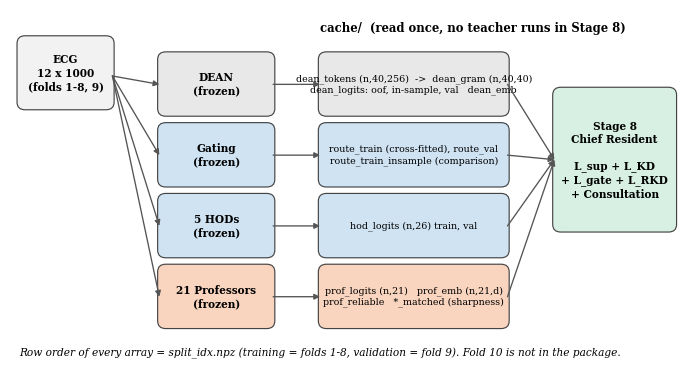

In [17]:
# Figure 1: the cache as a data-flow diagram
fig, ax = plt.subplots(figsize=(W2, 3.9)); ax.set_xlim(0, 100); ax.set_ylim(0, 56); ax.axis('off'); ax.grid(False)
def box(x, y, w, h, t, fc, fs=6.3, ec='#444444', bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.25,rounding_size=1.2', fc=fc, ec=ec, lw=0.7))
    ax.text(x + w / 2, y + h / 2, t, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.25)
def arrow(x0, y0, x1, y1, c='#555555'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', lw=0.8, color=c, shrinkA=0, shrinkB=0))
box(1, 41, 14, 11, 'ECG\n12 x 1000\n(folds 1-8, 9)', '#F2F2F2', bold=True)
teachers = [('DEAN\n(frozen)', 40, '#E8E8E8'), ('Gating\n(frozen)', 29, '#CFE3F3'), ('5 HODs\n(frozen)', 18, '#CFE3F3'), ('21 Professors\n(frozen)', 7, '#F9D5BF')]
for t, y, c in teachers:
    box(22, y, 17, 9.5, t, c, bold=True); arrow(15, 46, 22, y + 4.7)
outs = [('dean_tokens (n,40,256)  ->  dean_gram (n,40,40)\ndean_logits: oof, in-sample, val   dean_emb', 40, '#E8E8E8'),
        ('route_train (cross-fitted), route_val\nroute_train_insample (comparison)', 29, '#CFE3F3'),
        ('hod_logits (n,26) train, val', 18, '#CFE3F3'),
        ('prof_logits (n,21)   prof_emb (n,21,d)\nprof_reliable   *_matched (sharpness)', 7, '#F9D5BF')]
for (t, y, c), (_, yy, _) in zip(outs, teachers):
    box(46, y, 28, 9.5, t, c, fs=5.7); arrow(39, y + 4.7, 46, y + 4.7)
box(81, 22, 18, 22, 'Stage 8\nChief Resident\n\nL_sup + L_KD\n+ L_gate + L_RKD\n+ Consultation', '#D8F0E4', bold=True)
for (_, y, _) in teachers:
    arrow(74, y + 4.7, 81, 33)
ax.text(46, 53.5, 'cache/  (read once, no teacher runs in Stage 8)', fontsize=7, fontweight='bold', va='center')
ax.text(1, 3, 'Row order of every array = split_idx.npz (training = folds 1-8, validation = fold 9). Fold 10 is not in the package.', fontsize=6.3, va='center', style='italic')
save_fig(fig, 'fig01_cache_dataflow')

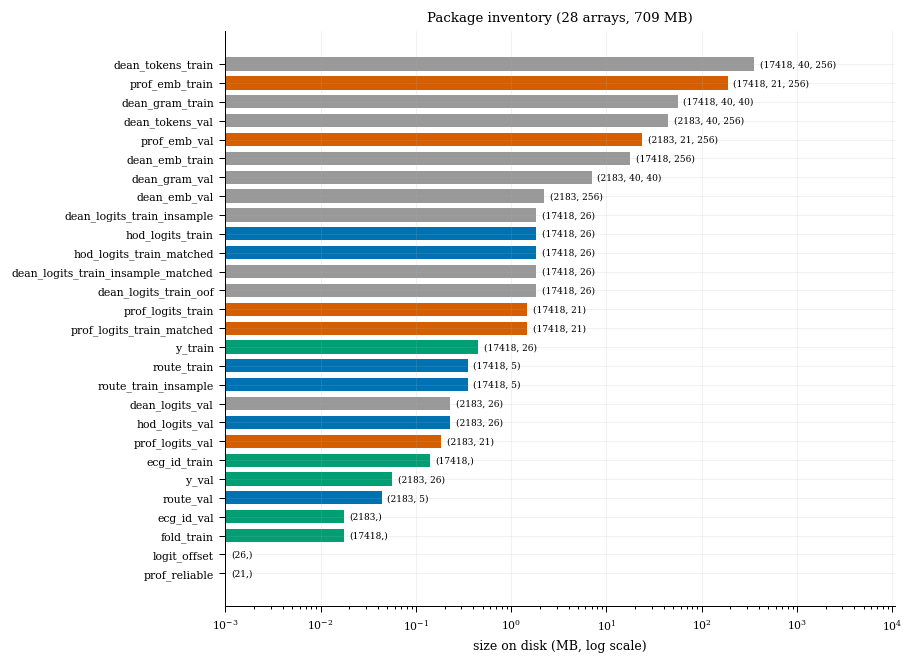

In [18]:
# Figure 2: inventory of the package
fig, ax = plt.subplots(figsize=(W2, 0.19 * len(INV) + 0.9))
I = INV.sort_values('MB')
col = ['#D55E00' if k.startswith('prof') else '#0072B2' if k.startswith(('hod', 'route')) else '#999999' if k.startswith('dean') else '#009E73' for k in I.array]
ax.barh(I.array, I.MB.clip(lower=1e-3), color=col, height=0.7); ax.set_xscale('log'); ax.set_xlabel('size on disk (MB, log scale)')
for i, (m, s_) in enumerate(zip(I.MB, I['shape'])):
    ax.text(max(m, 1e-3) * 1.15, i, f'{s_}', va='center', fontsize=5.4)
ax.set_xlim(1e-3, I.MB.max() * 30); ax.set_title(f'Package inventory ({len(INV)} arrays, {INV.MB.sum():.0f} MB)')
save_fig(fig, 'fig02_package_inventory')

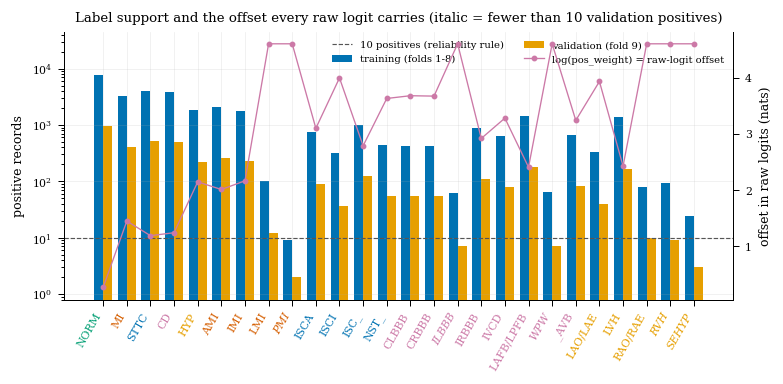

In [19]:
# Figure 3: label prevalence and the logit offset
fig, ax = plt.subplots(figsize=(W2, 2.9))
x = np.arange(26); w = 0.38
ax.bar(x - w / 2, Y_tr.sum(0), w, color='#0072B2', label='training (folds 1-8)')
ax.bar(x + w / 2, Y_va.sum(0), w, color='#E69F00', label='validation (fold 9)')
ax.axhline(CFG['min_pos'], color='#555555', ls='--', lw=0.7, label=f'{CFG["min_pos"]} positives (reliability rule)')
ax.set_yscale('log'); ax.set_ylim(0.8, max(Y_tr.sum(0).max(), 10) * 6); ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=60, ha='right'); ax.set_ylabel('positive records')
for t, l in zip(ax.get_xticklabels(), LABELS):
    fam = l if l in SUPER else FAMILY[l]
    t.set_color(SUPER_COL[fam])
    if l in LABELS and not REL[LABELS.index(l)]: t.set_fontstyle('italic')
ax2 = ax.twinx(); ax2.plot(x, LOGIT_OFFSET, 'o-', color='#CC79A7', ms=2.5, lw=0.8, label='log(pos_weight) = raw-logit offset'); ax2.set_ylabel('offset in raw logits (nats)'); ax2.grid(False); ax2.spines['right'].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc='upper right', ncol=2, fontsize=6)
ax.set_title('Label support and the offset every raw logit carries (italic = fewer than 10 validation positives)')
save_fig(fig, 'fig03_label_support_and_offset')

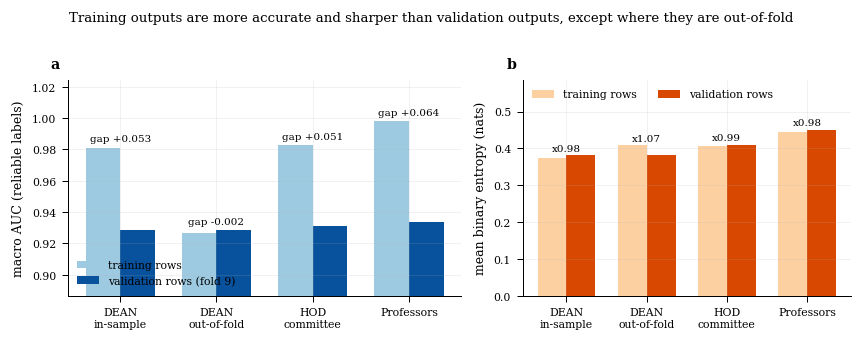

In [20]:
# Figure 4: the memorisation gap per source
fig, axs = plt.subplots(1, 2, figsize=(W2, 2.7), gridspec_kw=dict(width_ratios=[1.2, 1]))
names = list(SRC); x = np.arange(len(names)); w = 0.36
SHORT = ['DEAN\nin-sample', 'DEAN\nout-of-fold', 'HOD\ncommittee', 'Professors']
ax = axs[0]
ax.bar(x - w / 2, [SRC[n]['m_tr'] for n in names], w, color='#9ecae1', label='training rows'); ax.bar(x + w / 2, [SRC[n]['m_va'] for n in names], w, color='#08519c', label='validation rows (fold 9)')
for i, n in enumerate(names):
    ax.text(i, max(SRC[n]['m_tr'], SRC[n]['m_va']) + 0.004, f'gap {SRC[n]["m_tr"] - SRC[n]["m_va"]:+.3f}', ha='center', fontsize=6.2)
ax.set_xticks(x); ax.set_xticklabels(SHORT); lo_ = min(min(SRC[n]['m_tr'], SRC[n]['m_va']) for n in names); ax.set_ylim(max(0, lo_ - 0.04), 1.0 + 0.06 * (1 - lo_) + 0.02); ax.set_ylabel('macro AUC (reliable labels)'); ax.legend(loc='lower left'); panel(ax, 'a')
ax = axs[1]
H = AUDIT[['entropy_train', 'entropy_val']]
ax.bar(x - w / 2, H.entropy_train, w, color='#fdd0a2', label='training rows'); ax.bar(x + w / 2, H.entropy_val, w, color='#d94801', label='validation rows')
for i, n in enumerate(names): ax.text(i, max(H.iloc[i]) * 1.03, f'x{AUDIT.sharpness_ratio.iloc[i]:.2f}', ha='center', fontsize=6.2)
ax.set_xticks(x); ax.set_xticklabels(SHORT); ax.set_ylim(0, H.values.max() * 1.3); ax.set_ylabel('mean binary entropy (nats)'); ax.legend(loc='upper left', ncol=2); panel(ax, 'b')
fig.suptitle('Training outputs are more accurate and sharper than validation outputs, except where they are out-of-fold', y=1.02, fontsize=8)
fig.tight_layout(); save_fig(fig, 'fig04_memorisation_and_sharpness_gap')

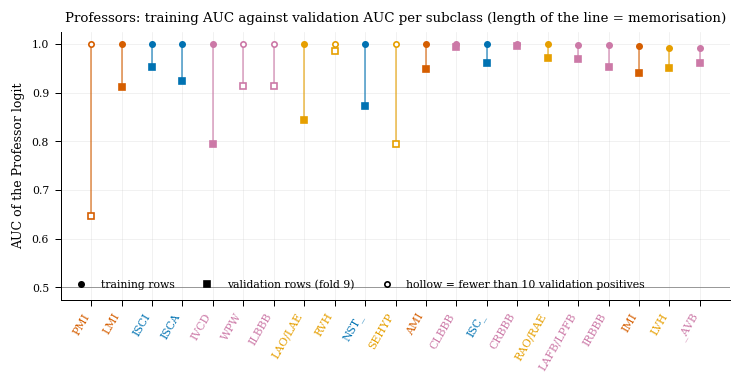

In [21]:
# Figure 5: per-subclass gap of the Professors
s = SRC['Professors']; o = np.argsort(-s['auc_tr'])
fig, ax = plt.subplots(figsize=(W2, 2.9))
for k, j in enumerate(o):
    c = SUPER_COL[FAMILY[SUB[j]]]
    ax.plot([k, k], [s['auc_va'][j], s['auc_tr'][j]], color=c, lw=1.1, alpha=0.6)
    ax.plot(k, s['auc_tr'][j], 'o', ms=3.2, color=c, mfc='white' if not s['rel'][j] else c)
    ax.plot(k, s['auc_va'][j], 's', ms=3.2, color=c, mfc='white' if not s['rel'][j] else c)
ax.set_xticks(range(21)); ax.set_xticklabels([SUB[j] for j in o], rotation=60, ha='right')
for t, j in zip(ax.get_xticklabels(), o): t.set_color(SUPER_COL[FAMILY[SUB[j]]])
ax.set_ylabel('AUC of the Professor logit'); ax.axhline(0.5, color='#888888', lw=0.5)
ax.plot([], [], 'o', color='k', ms=3.2, label='training rows'); ax.plot([], [], 's', color='k', ms=3.2, label='validation rows (fold 9)'); ax.plot([], [], 'o', mfc='white', color='k', ms=3.2, label='hollow = fewer than 10 validation positives')
ax.legend(ncol=3, loc='lower left'); ax.set_title('Professors: training AUC against validation AUC per subclass (length of the line = memorisation)')
save_fig(fig, 'fig05_professor_gap_per_subclass')

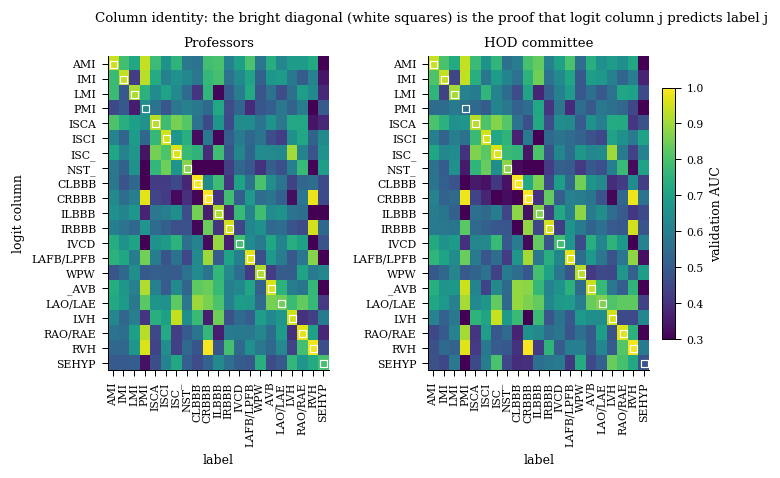

In [22]:
# Figure 6: do the columns mean what they say? AUC of each Professor column against each subclass label
fig, axs = plt.subplots(1, 2, figsize=(W2, 3.4), gridspec_kw=dict(width_ratios=[1, 1]))
for ax, name in zip(axs, ('Professors', 'HOD committee')):
    s = SRC[name]; sub_in = [i for i, c in enumerate(s['cols']) if c >= 5]
    M = column_identity(s['va'][:, sub_in], None, Y_va)
    im = ax.imshow(M, vmin=0.3, vmax=1.0, cmap='viridis', aspect='auto'); ax.grid(False)
    ax.set_xticks(range(21)); ax.set_xticklabels(SUB, rotation=90); ax.set_yticks(range(len(sub_in))); ax.set_yticklabels([SUB[s['cols'][i] - 5] for i in sub_in])
    ax.set_xlabel('label'); ax.set_ylabel('logit column' if name == 'Professors' else ''); ax.set_title(name)
    for k in range(len(sub_in)):
        ax.plot(s['cols'][sub_in[k]] - 5, k, 's', mfc='none', mec='white', ms=4.2, mew=0.7)
fig.subplots_adjust(wspace=0.45, right=0.88); cb = fig.colorbar(im, ax=axs, shrink=0.8, pad=0.02); cb.set_label('validation AUC')
fig.suptitle('Column identity: the bright diagonal (white squares) is the proof that logit column j predicts label j', y=0.99, fontsize=8)
save_fig(fig, 'fig06_column_identity')

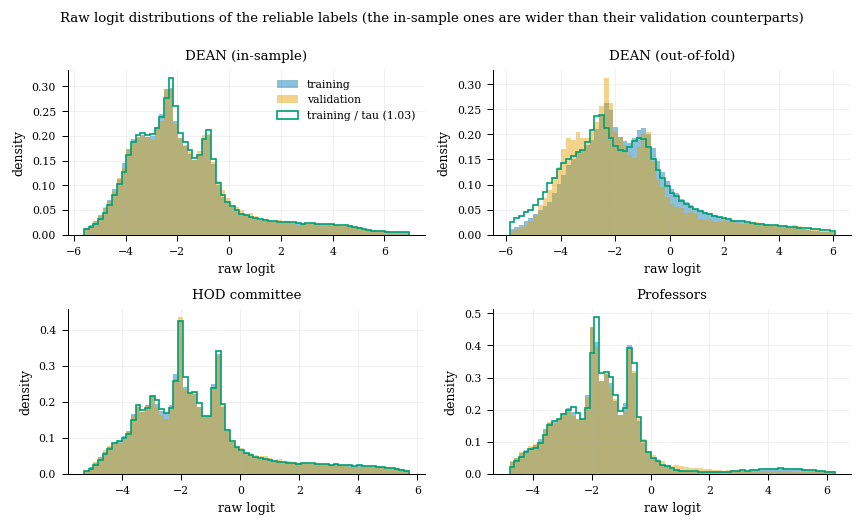

In [23]:
# Figure 7: logit distributions, training against validation
fig, axs = plt.subplots(2, 2, figsize=(W2, 4.3), sharey=False)
for ax, (name, s) in zip(axs.ravel(), SRC.items()):
    lo, hi = np.percentile(np.concatenate([s['tr'].ravel(), s['va'].ravel()]), [0.5, 99.5]); bins = np.linspace(lo, hi, 70)
    ax.hist(s['tr'][:, s['rel']].ravel(), bins, density=True, histtype='stepfilled', alpha=0.45, color='#0072B2', label='training')
    ax.hist(s['va'][:, s['rel']].ravel(), bins, density=True, histtype='stepfilled', alpha=0.45, color='#E69F00', label='validation')
    ax.hist(s['tr_matched'][:, s['rel']].ravel(), bins, density=True, histtype='step', color='#009E73', lw=1.0, label=f'training / tau ({s["tau"]:.2f})')
    ax.set_title(name); ax.set_xlabel('raw logit'); ax.set_ylabel('density')
    if name == 'DEAN (in-sample)': ax.legend()
fig.suptitle('Raw logit distributions of the reliable labels (the in-sample ones are wider than their validation counterparts)', y=1.0, fontsize=8)
fig.tight_layout(); save_fig(fig, 'fig07_logit_distributions')

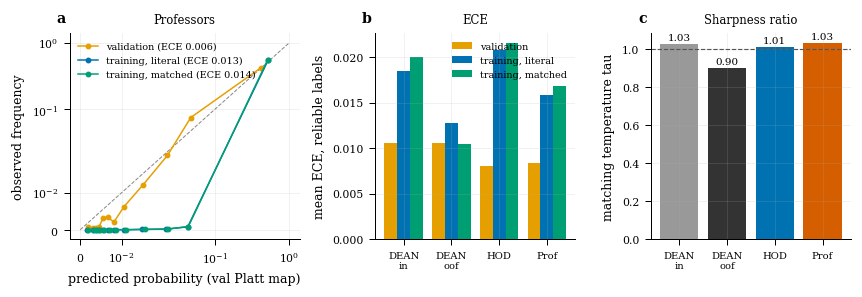

In [24]:
# Figure 8: what sharpness matching does to calibration on training rows
fig, axs = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
ax = axs[0]; ax.plot([0, 1], [0, 1], color='#888888', lw=0.6, ls='--')
s = SRC['Professors']; m = np.where(s['rel'])[0]
for lab, Z, Yy, c in (('validation', s['va'], Y_va, '#E69F00'), ('training, literal', s['tr'], Y_tr, '#0072B2'), ('training, matched', s['tr_matched'], Y_tr, '#009E73')):
    Pp = sigmoid(Z[:, m] * s['cal_a'][m] + s['cal_b'][m]); cf, ac, e = reliability(Yy[:, s['cols'][m]].ravel(), Pp.ravel(), 12)
    ax.plot(cf, ac, 'o-', ms=2.5, lw=0.9, color=c, label=f'{lab} (ECE {e:.3f})')
ax.set_xlabel('predicted probability (val Platt map)'); ax.set_ylabel('observed frequency'); ax.set_xscale('symlog', linthresh=0.02); ax.set_yscale('symlog', linthresh=0.02); ax.legend(fontsize=5.8); ax.set_title('Professors', fontsize=7); panel(ax, 'a')
ax = axs[1]; x = np.arange(len(names)); w = 0.27
ax.bar(x - w, [SRC[n]['ece_va'] for n in names], w, color='#E69F00', label='validation'); ax.bar(x, [SRC[n]['ece_tr'] for n in names], w, color='#0072B2', label='training, literal'); ax.bar(x + w, [SRC[n]['ece_tr_matched'] for n in names], w, color='#009E73', label='training, matched')
ax.set_xticks(x); ax.set_xticklabels(['DEAN\nin', 'DEAN\noof', 'HOD', 'Prof'], fontsize=6); ax.set_ylabel('mean ECE, reliable labels'); ax.legend(fontsize=5.8); ax.set_title('ECE', fontsize=7); panel(ax, 'b')
ax = axs[2]; ax.bar(x, [SRC[n]['tau'] for n in names], color=[SRC_COL[n] for n in names]); ax.axhline(1, color='#555555', lw=0.7, ls='--')
for i, n in enumerate(names): ax.text(i, SRC[n]['tau'] * 1.02, f'{SRC[n]["tau"]:.2f}', ha='center', fontsize=6.2)
ax.set_xticks(x); ax.set_xticklabels(['DEAN\nin', 'DEAN\noof', 'HOD', 'Prof'], fontsize=6); ax.set_ylabel('matching temperature tau'); ax.set_title('Sharpness ratio', fontsize=7); panel(ax, 'c')
fig.tight_layout(); save_fig(fig, 'fig08_sharpness_matching')

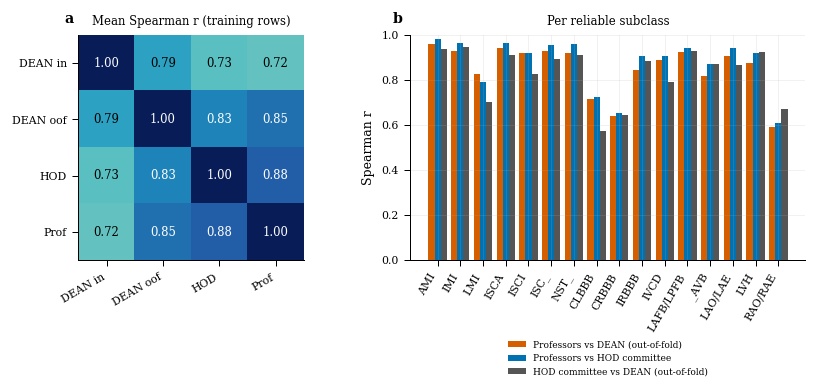

In [25]:
# Figure 9: agreement between the sources on the training rows
def ranks(S): return np.apply_along_axis(rankdata, 0, S)
subs = {n: SRC[n]['tr'][:, 5 - SRC[n]['off']:] if SRC[n]['off'] == 0 else SRC[n]['tr'] for n in names}
R_ = {n: ranks(v[:, REL_SUB]) for n, v in subs.items()}
def col_corr(a, b): return np.array([np.corrcoef(a[:, j], b[:, j])[0, 1] for j in range(a.shape[1])])
Cm = np.eye(len(names)); CC = {}
for i, a in enumerate(names):
    for j, b in enumerate(names):
        if i < j:
            CC[(a, b)] = col_corr(R_[a], R_[b]); Cm[i, j] = Cm[j, i] = np.nanmean(CC[(a, b)])
fig, axs = plt.subplots(1, 2, figsize=(W2, 3.6), gridspec_kw=dict(width_ratios=[1, 1.25]))
ax = axs[0]; im = ax.imshow(Cm, vmin=0.5, vmax=1, cmap='YlGnBu'); ax.grid(False)
ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(['DEAN in', 'DEAN oof', 'HOD', 'Prof'], rotation=30, ha='right'); ax.set_yticklabels(['DEAN in', 'DEAN oof', 'HOD', 'Prof'])
for i in range(4):
    for j in range(4): ax.text(j, i, f'{Cm[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if Cm[i, j] > 0.8 else 'black')
ax.set_title('Mean Spearman r (training rows)', fontsize=7); panel(ax, 'a')
ax = axs[1]; rel_names = [SUB[k] for k in np.where(REL_SUB)[0]]; xx = np.arange(len(rel_names)); w = 0.27
for k, (pair, c) in enumerate((((names[3], names[1]), '#D55E00'), ((names[3], names[2]), '#0072B2'), ((names[2], names[1]), '#555555'))):
    ax.bar(xx + (k - 1) * w, CC[(pair[1], pair[0])] if (pair[1], pair[0]) in CC else CC[pair], w, color=c, label=f'{pair[0]} vs {pair[1]}')
ax.set_xticks(xx); ax.set_xticklabels(rel_names, rotation=60, ha='right'); ax.set_ylim(0, 1); ax.set_ylabel('Spearman r'); ax.legend(fontsize=5.4, loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=1); ax.set_title('Per reliable subclass', fontsize=7); panel(ax, 'b')
fig.tight_layout(); save_fig(fig, 'fig09_source_agreement')

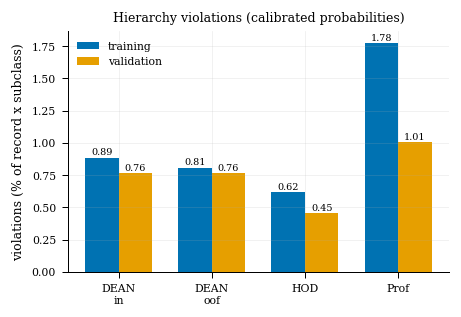

In [26]:
# Figure 10: hierarchy violations
fig, ax = plt.subplots(figsize=(W1 + 0.6, 2.6)); x = np.arange(len(names)); w = 0.36
H_ = HIER.pivot(index='source', columns='split', values='violation_rate').loc[names]
ax.bar(x - w / 2, H_['train'] * 100, w, color='#0072B2', label='training'); ax.bar(x + w / 2, H_['val'] * 100, w, color='#E69F00', label='validation')
for i, n in enumerate(names): ax.text(i - w / 2, H_['train'].iloc[i] * 100 + 0.02, f'{H_["train"].iloc[i] * 100:.2f}', ha='center', fontsize=5.8); ax.text(i + w / 2, H_['val'].iloc[i] * 100 + 0.02, f'{H_["val"].iloc[i] * 100:.2f}', ha='center', fontsize=5.8)
ax.set_xticks(x); ax.set_xticklabels(['DEAN\nin', 'DEAN\noof', 'HOD', 'Prof']); ax.set_ylabel('violations (% of record x subclass)'); ax.legend(); ax.set_title('Hierarchy violations (calibrated probabilities)', fontsize=7.5)
save_fig(fig, 'fig10_hierarchy_violations')

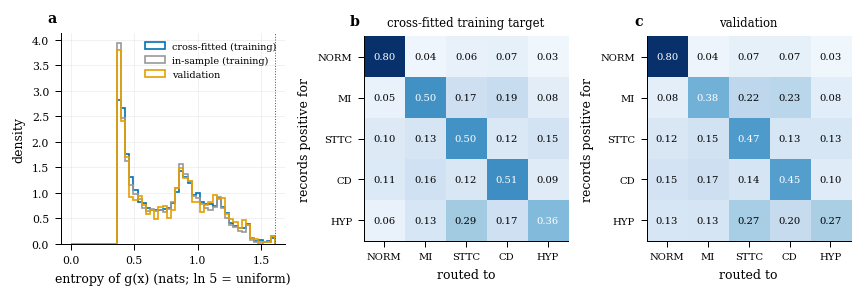

In [27]:
# Figure 11: the gate-mimic target
def ent(R): return -(R * np.log(R)).sum(1)
fig, axs = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
ax = axs[0]; bins = np.linspace(0, np.log(5), 50)
for lab, R, c in (('cross-fitted (training)', RT, '#0072B2'), ('in-sample (training)', RTI, '#999999'), ('validation', RV, '#E69F00')):
    ax.hist(ent(R), bins, density=True, histtype='step', lw=1.1, color=c, label=lab)
ax.axvline(np.log(5), color='#555555', ls=':', lw=0.6); ax.set_xlabel('entropy of g(x) (nats; ln 5 = uniform)'); ax.set_ylabel('density'); ax.legend(fontsize=5.8); panel(ax, 'a')
for ax, (R, Y, t, lab) in zip(axs[1:], ((RT, Y_tr, 'cross-fitted training target', 'b'), (RV, Y_va, 'validation', 'c'))):
    Mx = np.array([R[Y[:, c] > 0].mean(0) for c in range(5)])
    im = ax.imshow(Mx, cmap='Blues', vmin=0, vmax=max(0.6, Mx.max())); ax.grid(False)
    ax.set_xticks(range(5)); ax.set_xticklabels(SUPER, fontsize=6); ax.set_yticks(range(5)); ax.set_yticklabels(SUPER, fontsize=6); ax.set_xlabel('routed to'); ax.set_ylabel('records positive for')
    for i in range(5):
        for j in range(5): ax.text(j, i, f'{Mx[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if Mx[i, j] > 0.35 else 'black')
    ax.set_title(t, fontsize=7); panel(ax, lab)
fig.tight_layout(); save_fig(fig, 'fig11_routing_targets')

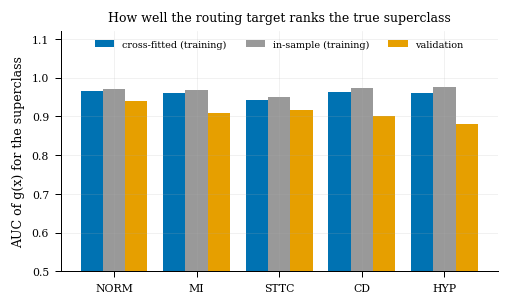

In [28]:
# Figure 12: routing AUC per superclass, cross-fitted against in-sample
fig, ax = plt.subplots(figsize=(W1 + 1.2, 2.6)); x = np.arange(5); w = 0.27
for k, (key, lab, c) in enumerate((('cross_fitted', 'cross-fitted (training)', '#0072B2'), ('in_sample', 'in-sample (training)', '#999999'), ('validation', 'validation', '#E69F00'))):
    ax.bar(x + (k - 1) * w, ROUTE[key]['auc'], w, color=c, label=lab)
ax.set_xticks(x); ax.set_xticklabels(SUPER); ax.set_ylim(0.5, 1.12); ax.set_ylabel('AUC of g(x) for the superclass'); ax.legend(fontsize=5.8, loc='upper center', ncol=3); ax.set_title('How well the routing target ranks the true superclass', fontsize=7.5)
save_fig(fig, 'fig12_routing_auc')

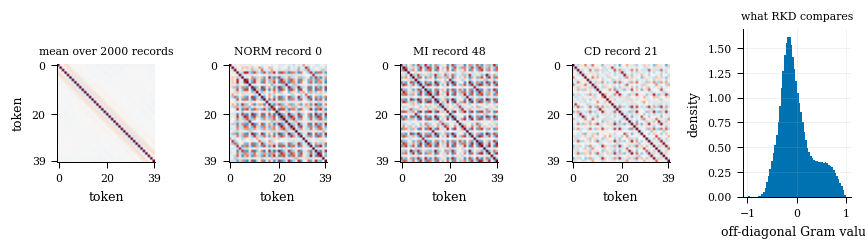

In [29]:
# Figure 13: DEAN token Gram matrices
pos = {c: np.where(Y_tr[:, c] > 0)[0] for c in range(5)}
ex = [(SUPER[c], pos[c][0]) for c in (0, 1, 3) if len(pos[c])]
fig, axs = plt.subplots(1, len(ex) + 2, figsize=(W2, 2.1), gridspec_kw=dict(width_ratios=[1] * (len(ex) + 1) + [1.1]))
mean_g = GRAM_TR[:2000].astype(np.float32).mean(0)
axs[0].imshow(mean_g, vmin=-1, vmax=1, cmap='RdBu_r'); axs[0].set_title('mean over 2000 records', fontsize=6.5); axs[0].grid(False)
for ax, (lab, i) in zip(axs[1:len(ex) + 1], ex):
    ax.imshow(GRAM_TR[i].astype(np.float32), vmin=-1, vmax=1, cmap='RdBu_r'); ax.set_title(f'{lab} record {i}', fontsize=6.5); ax.grid(False)
for ax in axs[:len(ex) + 1]: ax.set_xlabel('token'); ax.set_xticks([0, 20, 39]); ax.set_yticks([0, 20, 39])
axs[0].set_ylabel('token')
ax = axs[-1]; ax.hist(g32[:, off].ravel(), 60, density=True, color='#0072B2'); ax.set_xlabel('off-diagonal Gram value'); ax.set_ylabel('density'); ax.set_title('what RKD compares', fontsize=6.5)
fig.tight_layout(); save_fig(fig, 'fig13_dean_token_gram')

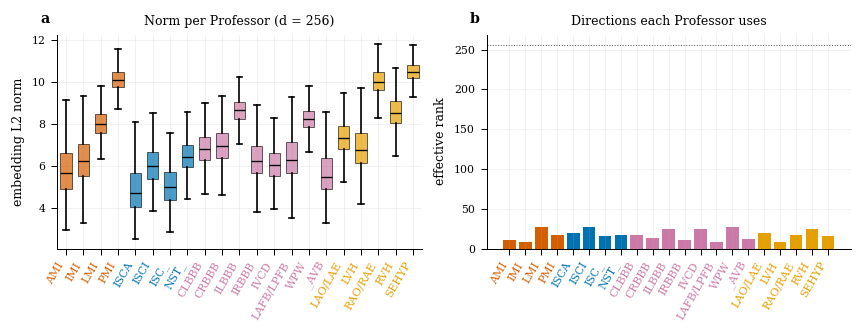

In [30]:
# Figure 14: Professor embeddings, scale and effective rank
fig, axs = plt.subplots(1, 2, figsize=(W2, 2.8)); o = np.argsort([SUPER.index(FAMILY[s_]) * 100 + k for k, s_ in enumerate(SUB)]); cols = [SUPER_COL[FAMILY[SUB[j]]] for j in o]
ax = axs[0]; bp = ax.boxplot([norms[:, j] for j in o], patch_artist=True, showfliers=False, widths=0.65, medianprops=dict(color='k', lw=0.8))
for p, c in zip(bp['boxes'], cols): p.set_facecolor(c); p.set_alpha(0.7); p.set_linewidth(0.5)
ax.set_xticklabels([SUB[j] for j in o], rotation=60, ha='right'); ax.set_ylabel('embedding L2 norm'); ax.set_title(f'Norm per Professor (d = {D_PEMB})', fontsize=7.5); panel(ax, 'a')
ax = axs[1]; ax.bar(range(21), ER[o], color=cols); ax.set_xticks(range(21)); ax.set_xticklabels([SUB[j] for j in o], rotation=60, ha='right'); ax.set_ylabel('effective rank'); ax.axhline(D_PEMB, color='#555555', ls=':', lw=0.6); ax.set_title('Directions each Professor uses', fontsize=7.5); panel(ax, 'b')
for a_ in axs:
    for t, c in zip(a_.get_xticklabels(), cols): t.set_color(c)
fig.tight_layout(); save_fig(fig, 'fig14_professor_embeddings')

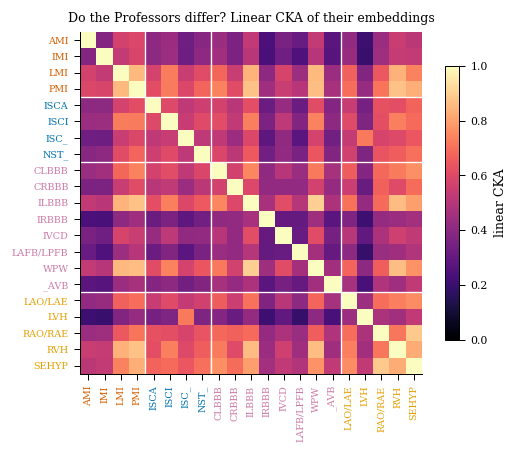

In [31]:
# Figure 15: similarity between Professors
fig, ax = plt.subplots(figsize=(W1 + 1.4, 3.7)); Cx = CKA[np.ix_(o, o)]
im = ax.imshow(Cx, vmin=0, vmax=1, cmap='magma'); ax.grid(False)
ax.set_xticks(range(21)); ax.set_xticklabels([SUB[j] for j in o], rotation=90, fontsize=5.8); ax.set_yticks(range(21)); ax.set_yticklabels([SUB[j] for j in o], fontsize=5.8)
for t_ax in (ax.get_xticklabels(), ax.get_yticklabels()):
    for t, c in zip(t_ax, cols): t.set_color(c)
fam_o = [FAMILY[SUB[j]] for j in o]; edges = [i for i in range(1, 21) if fam_o[i] != fam_o[i - 1]]
for e in edges: ax.axhline(e - 0.5, color='white', lw=0.8); ax.axvline(e - 0.5, color='white', lw=0.8)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label('linear CKA'); ax.set_title('Do the Professors differ? Linear CKA of their embeddings', fontsize=7.5)
save_fig(fig, 'fig15_professor_cka')

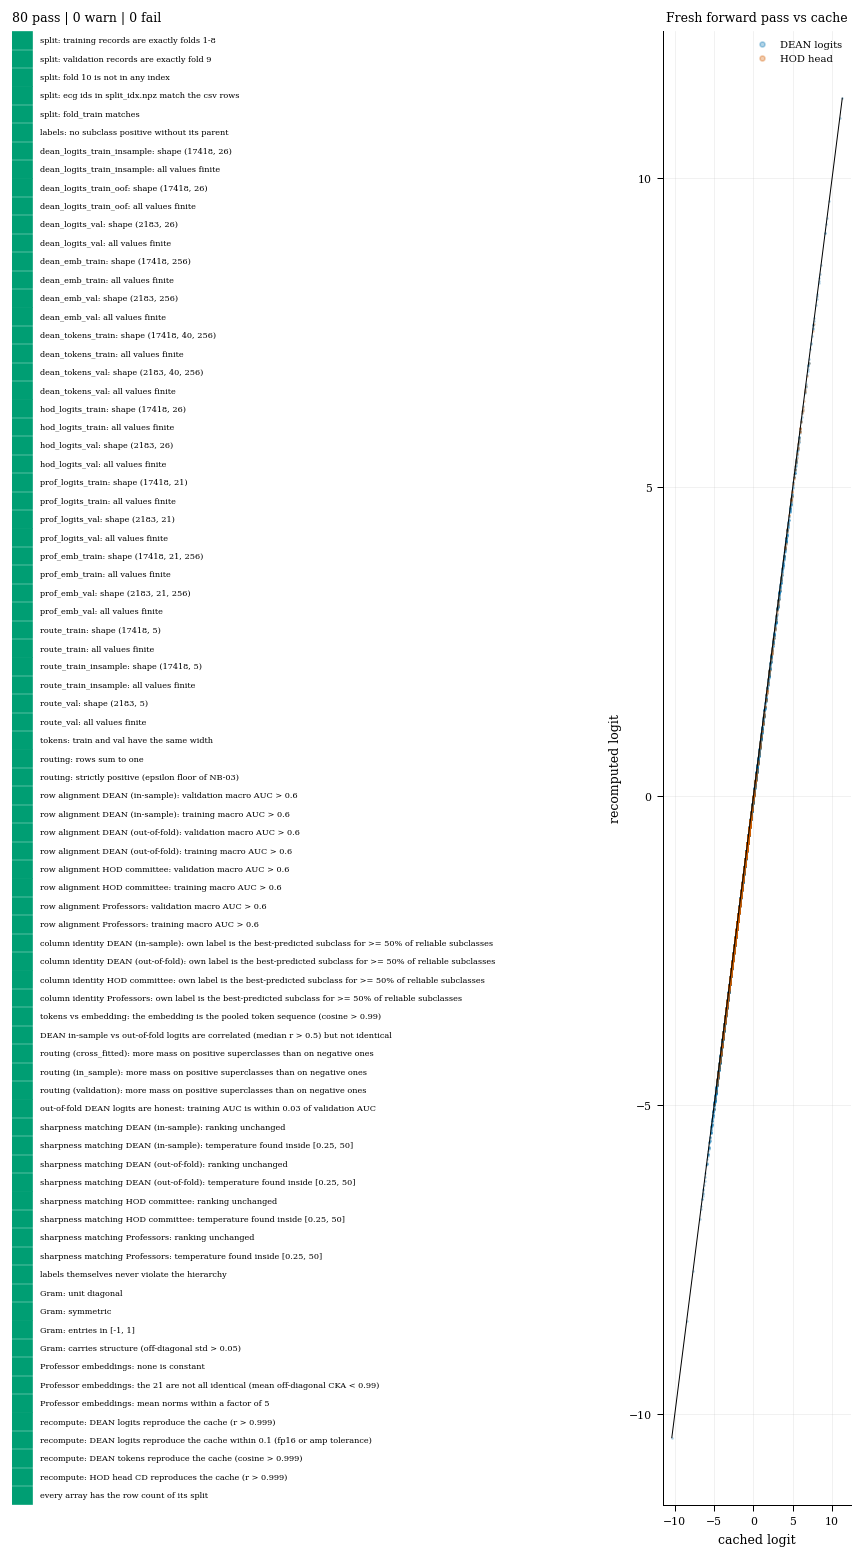

In [32]:
# Figure 16: the evidence table as a figure, and the recompute check
CK = pd.DataFrame(CHECKS)
fig = plt.figure(figsize=(W2, max(3.0, 0.155 * len(CK) + 0.6))); gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])
ax = fig.add_subplot(gs[0]); ax.axis('off'); ax.grid(False)
cmap_ = {'PASS': '#009E73', 'WARN': '#E69F00', 'FAIL': '#D55E00'}
for i, r in CK.iterrows():
    y = 1 - (i + 0.5) / len(CK); ax.add_patch(plt.Rectangle((0, y - 0.45 / len(CK)), 0.035, 0.9 / len(CK), color=cmap_[r.status], transform=ax.transAxes))
    ax.text(0.05, y, r.check[:125], va='center', fontsize=4.9, transform=ax.transAxes)
ax.set_title(f'{(CK.status == "PASS").sum()} pass | {(CK.status == "WARN").sum()} warn | {(CK.status == "FAIL").sum()} fail', fontsize=7.5, loc='left')
ax = fig.add_subplot(gs[1])
if RECOMP:
    c_, r_ = RECOMP['dean_logits']; ax.plot(c_.ravel(), r_.ravel(), '.', ms=1, alpha=0.3, color='#0072B2', label='DEAN logits')
    if 'hod_logits' in RECOMP: c2, r2_ = RECOMP['hod_logits']; ax.plot(c2.ravel(), r2_.ravel(), '.', ms=1, alpha=0.3, color='#D55E00', label='HOD head')
    lim = [min(c_.min(), r_.min()), max(c_.max(), r_.max())]; ax.plot(lim, lim, color='k', lw=0.6); ax.set_xlabel('cached logit'); ax.set_ylabel('recomputed logit'); ax.legend(markerscale=6, fontsize=6); ax.set_title('Fresh forward pass vs cache', fontsize=7.5)
else:
    ax.axis('off'); ax.text(0.5, 0.5, f'recompute check\n{RECOMP_STATUS}', ha='center', va='center', wrap=True, fontsize=6.5)
fig.tight_layout(); save_fig(fig, 'fig16_checks_and_recompute')

## 13. Evidence table and gate
Every check of this notebook in one table. A **FAIL** means a cached array is not what it claims to be, and the export below refuses to run (set `CFG['strict'] = False` only to inspect a broken cache, never to publish it). A **WARN** is something to read, not a blocker.

In [33]:
CK = pd.DataFrame(CHECKS); CK.to_csv(os.path.join(TAB_DIR, 'table_checks.csv'), index=False)
with pd.option_context('display.max_colwidth', 110, 'display.width', 220):
    print(CK.to_string(index=False))
n_fail = int((CK.status == 'FAIL').sum())
print(f'\n{(CK.status == "PASS").sum()} PASS | {(CK.status == "WARN").sum()} WARN | {n_fail} FAIL')
if CFG['strict']:
    assert n_fail == 0, 'Failed checks: ' + '; '.join(CK[CK.status == 'FAIL'].check.tolist())

                                                                                                         check status                          detail
                                                                 split: training records are exactly folds 1-8   PASS                                
                                                                  split: validation records are exactly fold 9   PASS                                
                                                                            split: fold 10 is not in any index   PASS                                
                                                            split: ecg ids in split_idx.npz match the csv rows   PASS                                
                                                                                     split: fold_train matches   PASS                                
                                                               labels: no subclass positive without 

## 14. Export
Arrays are written one by one with `np.save`, then re-read to record shape, dtype and md5 in the manifest. `cache_lib.verify_cache(deep=True)` finally re-opens the package exactly as Stage 8 will.

In [34]:
man_arrays = OrderedDict()
for k, v in ARR.items():
    fn = os.path.join('cache', k + '.npy')
    np.save(os.path.join(WORK, fn), np.ascontiguousarray(v))
    p = os.path.join(WORK, fn)
    man_arrays[k] = dict(file=fn, shape=list(v.shape), dtype=str(v.dtype), bytes=os.path.getsize(p), md5=md5_file(p), source=SOURCE[k])
manifest = dict(
    schema_version=cache_lib.SCHEMA_VERSION, stage=7, created=time.strftime('%Y-%m-%d %H:%M:%S'), versions=VERSIONS,
    n_train=int(NTR), n_val=int(NVA), row_key='split_idx.npz: train_idx (folds 1-8), val_idx (fold 9); ecg_id_* hold the keys', fold_10='never included',
    label_order=LABELS, subclass_order=SUB, family=FAMILY, prof_columns='prof_* column j = subclass SUB[j]', prof_emb_dim=int(D_PEMB), dean_token_shape=[40, int(D_TOK)],
    logit_note='raw logits include log(pos_weight) = logit_offset; calibration maps are in cache_report.json', min_pos=CFG['min_pos'],
    sharpness_tau={k: v['tau'] for k, v in TAU.items()}, arrays=man_arrays)
json.dump(manifest, open(os.path.join(WORK, cache_lib.MANIFEST), 'w'), indent=1)
report = dict(cfg=CFG, checks=CHECKS, target_audit=AUDIT.reset_index().to_dict('records'), sharpness=TAU, hierarchy=HIER.to_dict('records'),
              calibration_fold9=CAL, recompute=RECOMP_STATUS, reliable_labels=[LABELS[i] for i in np.where(REL)[0]], unreliable_labels=[LABELS[i] for i in np.where(~REL)[0]],
              routing={k: dict(mass_pos=v['mass_pos'], mass_neg=v['mass_neg'], auc=v['auc'].tolist()) for k, v in ROUTE.items()},
              artefacts={k: dict(path=v['path'].replace(INPUT_ROOT, '<input>').replace(WORK, '<work>'), copies=v['copies']) for k, v in REG.items()})
json.dump(report, open(os.path.join(WORK, 'cache_report.json'), 'w'), indent=1, default=float)
problems = cache_lib.verify_cache(WORK, deep=True)
assert not problems, problems
man2, arr2 = cache_lib.load_cache(WORK)
assert np.array_equal(arr2['y_val'], Y_va) and np.allclose(arr2['prof_logits_val'], A['prof_logits_val'])
print(f'cache verified: {len(arr2)} arrays, {sum(m["bytes"] for m in man_arrays.values()) / 1e6:.0f} MB')
print(f'total notebook time {(time.time() - NB_T0) / 60:.1f} min')
for root, _, files in os.walk(WORK):
    if '__pycache__' in root: continue
    for f in sorted(files):
        if f.endswith('.pdf'): continue
        print(f'  {os.path.relpath(os.path.join(root, f), WORK):48s} {os.path.getsize(os.path.join(root, f)) / 1e6:9.2f} MB')

cache verified: 28 arrays, 709 MB
total notebook time 2.0 min
  __notebook__.ipynb                                    1.52 MB
  cache_lib.py                                          0.00 MB
  cache_report.json                                     0.02 MB
  dean_lib.py                                           0.01 MB
  eval_lib.py                                           0.01 MB
  hod_lib.py                                            0.01 MB
  teacher_cache_manifest.json                           0.01 MB
  figures/fig01_cache_dataflow.png                      0.20 MB
  figures/fig02_package_inventory.png                   0.26 MB
  figures/fig03_label_support_and_offset.png            0.23 MB
  figures/fig04_memorisation_and_sharpness_gap.png      0.14 MB
  figures/fig05_professor_gap_per_subclass.png          0.16 MB
  figures/fig06_column_identity.png                     0.16 MB
  figures/fig07_logit_distributions.png                 0.14 MB
  figures/fig08_sharpness_matching.png    

## 15. After this notebook
1. **Publish** `/kaggle/working` as the Dataset `cached-teacher-outputs-v1` (Save Version, then "New Dataset from Output"). Stage 8 attaches only this Dataset, plus `ptbxl-processed-v1` for the ECG signals.
2. **Stage 8 loads it** with `import cache_lib; man, C = cache_lib.load_cache('/kaggle/input/cached-teacher-outputs-v1')` (arrays are memory-mapped; indexing by batch indices reads only those rows).
3. **Read `table_target_audit.csv` and `table_sharpness_matching.csv` before choosing Stage 8 targets.** If the Professors' memorisation gap is large (training AUC near 1.0 against about 0.93 validation), the literal Professor logits mostly repeat the training labels, and the honest comparison for Stage 8 is:

| Arm | Logit target | Purpose |
|---|---|---|
| A | none (supervised only) | baseline |
| B | `dean_logits_train_oof` | the only out-of-fold teacher |
| C | `hod_logits_train_matched` | HOD level, matched sharpness |
| D | `prof_logits_train_matched` | the synopsis target with the calibration problem reduced |
| E | `prof_logits_train` (literal) | the synopsis target as written |
| F | D plus Consultation over `prof_emb_*` | the full proposal |

   The hierarchy claim stands only if D or F beats B at a paired confidence interval that excludes zero on fold 9. If it does not, report that plainly: it is a result.
4. **Gate target** is `route_train` (cross-fitted), never `route_train_insample`.
5. **Relational target** is `dean_gram_*`; the student computes its own Gram with `cache_lib.token_gram_np`-equivalent torch code on its 40 tokens (the student must also produce 40 tokens, which the 25-sample patch of this project does).
6. **Fold 10** stays untouched until Stage 10.